## Step 1 — Import Libraries and Load the Cleaned Dataset

### Objective

This notebook presents the **Exploratory Data Analysis (EDA) and Time Series Analysis** of the Walmart M5 retail dataset, using the cleaned and validated data produced during the data preparation phase.

The primary objective is to investigate historical retail demand patterns, identify factors associated with demand fluctuations, and generate insights that will guide **feature engineering, model selection, and forecasting strategy**.

### Key Research Questions

The analysis aims to address the following questions:

1. **Overall Demand:** How has retail demand evolved over time, and what are its main characteristics?
2. **Seasonality:** What weekly, monthly, and yearly patterns are present in historical demand?
3. **Geographical Differences:** How does demand vary across states and individual stores?
4. **Product Categories:** Which categories contribute most to demand, and how do their patterns differ?
5. **Holidays and Events:** How does demand differ on holidays and special-event days compared with regular days?
6. **SNAP Availability:** What differences in demand are observed between SNAP and non-SNAP days?
7. **Pricing Dynamics:** What relationships exist between average selling prices, weekly price changes, and retail demand?

### Dataset Overview

The cleaned dataset contains **57,390 observations and 19 columns**, representing **30 store-category time series** across 10 stores, 3 states, and 3 product categories.

The data covers **1,913 consecutive days**, from January 29, 2011, to April 24, 2016, at the **store × category × day** level.

This aggregation preserves meaningful differences in retail demand while maintaining a manageable dataset for time series analysis and machine learning.

### Expected Outcome

The findings from this notebook will inform the selection of calendar features, historical demand lags, rolling statistics, pricing variables, and other relevant predictors for the subsequent forecasting models.

The analysis will focus on identifying **patterns and associations rather than establishing causal relationships**, particularly when examining holidays, SNAP availability, and pricing effects.


In [25]:
# Step 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# 1b. Load the cleaned dataset created in Notebook 1

file_path = "../outputs/m5_cleaned_store_category_daily.csv"

df = pd.read_csv(file_path)

# Convert date back to datetime format
df["date"] = pd.to_datetime(df["date"])

print("Cleaned dataset loaded successfully.")
print("Shape:", df.shape)

Cleaned dataset loaded successfully.
Shape: (57390, 19)


## Step 2 — Initial Inspection

Before beginning the exploratory analysis, we verify that the cleaned dataset has been loaded correctly and inspect its structure.

This step confirms the number of observations, variables, data types, and the main dimensions of the dataset. It also provides a final check that the dataset used for EDA is the same cleaned dataset produced in Notebook 1.


In [4]:
# Display the first five rows

df.head()

,store_id,state_id,category,day_id,demand,date,wm_yr_wk,weekday,weekday_num,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap,avg_sell_price,price_change,price_change_pct
0,CA_1,CA,FOODS,d_1,3239,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,3.14922,NaN,NaN
1,CA_1,CA,FOODS,d_2,3137,2011-01-30,11101,Sunday,2,1,2011,NaN,NaN,NaN,NaN,0,3.14922,NaN,NaN
2,CA_1,CA,FOODS,d_3,2008,2011-01-31,11101,Monday,3,1,2011,NaN,NaN,NaN,NaN,0,3.14922,NaN,NaN
3,CA_1,CA,FOODS,d_4,2258,2011-02-01,11101,Tuesday,4,2,2011,NaN,NaN,NaN,NaN,1,3.14922,NaN,NaN
4,CA_1,CA,FOODS,d_5,2032,2011-02-02,11101,Wednesday,5,2,2011,NaN,NaN,NaN,NaN,1,3.14922,NaN,NaN


In [5]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57390 entries, 0 to 57389
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   store_id          57390 non-null  object        
 1   state_id          57390 non-null  object        
 2   category          57390 non-null  object        
 3   day_id            57390 non-null  object        
 4   demand            57390 non-null  int64         
 5   date              57390 non-null  datetime64[ns]
 6   wm_yr_wk          57390 non-null  int64         
 7   weekday           57390 non-null  object        
 8   weekday_num       57390 non-null  int64         
 9   month             57390 non-null  int64         
 10  year              57390 non-null  int64         
 11  event_name_1      4620 non-null   object        
 12  event_type_1      4620 non-null   object        
 13  event_name_2      120 non-null    object        
 14  event_type_2      120 

In [6]:
# Check the main dimensions

print("Number of observations:", len(df))
print("Number of columns:", df.shape[1])
print("Number of stores:", df["store_id"].nunique())
print("Number of states:", df["state_id"].nunique())
print("Number of categories:", df["category"].nunique())
print("Number of dates:", df["date"].nunique())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

Number of observations: 57390
Number of columns: 19
Number of stores: 10
Number of states: 3
Number of categories: 3
Number of dates: 1913

Date range:
2011-01-29 00:00:00 to 2016-04-24 00:00:00


#### Interpretation — Dataset Structure, Data Types and Dataset Coverage

The cleaned dataset contains **57,390 daily observations and 19 columns** , covering **10 stores across 3 states and 3 product categories** which is an appropriate data types for exploratory analysis.

The `date` column is stored in datetime format, enabling chronological aggregation and time series visualization. Demand is represented numerically, while average selling prices and price-change features are stored as continuous variables.

Missing event information reflects dates without recorded events, while the 210 missing price-change observations are expected because the first week of each store-category series has no preceding weekly price.

The dataset represents 30 store-category time series, each containing 1,913 historical days from January 29, 2011, to April 24, 2016.

This balanced panel structure enables consistent comparisons across stores, states, and product categories while supporting the investigation of historical demand patterns and seasonality.

The dataset provides a suitable foundation for subsequent exploratory analysis and store-category-level demand forecasting.

Overall, the dataset is correctly structured for investigating historical retail demand, seasonality, geographical differences, and potential relationships between demand and external factors.

## Step 3 - Descriptive Analysis of Retail Demand
**Research question:**
- What are the typical demand levels, variability, and distribution of daily retail demand across Walmart's store-category combinations?

**Demand** is the target variable that the forecasting model will ultimately predict.

Before examining individual stores, categories, or seasonal effects, we first investigate the overall distribution of demand across the complete dataset.

This provides a baseline understanding of the scale and variability of retail demand.


In [7]:
# 3.1 Descriptive statistics for daily demand

df["demand"].describe()


count    57390.000000
mean      1144.718749
std       1049.785911
min          0.000000
25%        354.000000
50%        702.000000
75%       1734.000000
max       6488.000000
Name: demand, dtype: float64

In [10]:
# 3.2 Calculate key overall demand statistics

overall_total_demand = df["demand"].sum()
overall_avg_demand = df["demand"].mean()
overall_median_demand = df["demand"].median()
overall_std_demand = df["demand"].std()

print(f"Total demand: {overall_total_demand:,.0f} units")
print(f"Average demand per store-category-day: {overall_avg_demand:,.2f} units")
print(f"Median demand: {overall_median_demand:,.2f} units")
print(f"Standard deviation: {overall_std_demand:,.2f} units")
print(f"Minimum demand: {df['demand'].min():,.0f} units")
print(f"Maximum demand: {df['demand'].max():,.0f} units")

Total demand: 65,695,409 units
Average demand per store-category-day: 1,144.72 units
Median demand: 702.00 units
Standard deviation: 1,049.79 units
Minimum demand: 0 units
Maximum demand: 6,488 units


#### Interpretation — Descriptive Statistics of Retail Demand

The dataset records approximately **65.70 million units of total demand** over the historical observation period.

Average daily demand per store-category combination is **1,144.72 units**, while the median is **702 units**. The difference between these values suggests a positively skewed distribution, with higher-demand observations pulling the mean upward.

Demand ranges from **0 to 6,488 units**, with a standard deviation of approximately **1,049.79 units**, indicating substantial variation across store-category-day observations.

The middle 50% of observations fall between **354 and 1,734 units**, further demonstrating differences in demand levels.

**Implication for forecasting:** Demand varies considerably across store-category combinations. Forecasting models should account for differences in demand scale and historical patterns rather than assuming uniform demand behavior across all series.

### 3.3 — Distribution of Daily Retail Demand

A histogram with a kernel density estimate (KDE) is used to examine the distribution of daily demand. The mean and median are highlighted to assess skewness and identify differences in demand levels.

This analysis helps determine whether demand is evenly distributed or concentrated among lower- and higher-demand observations.

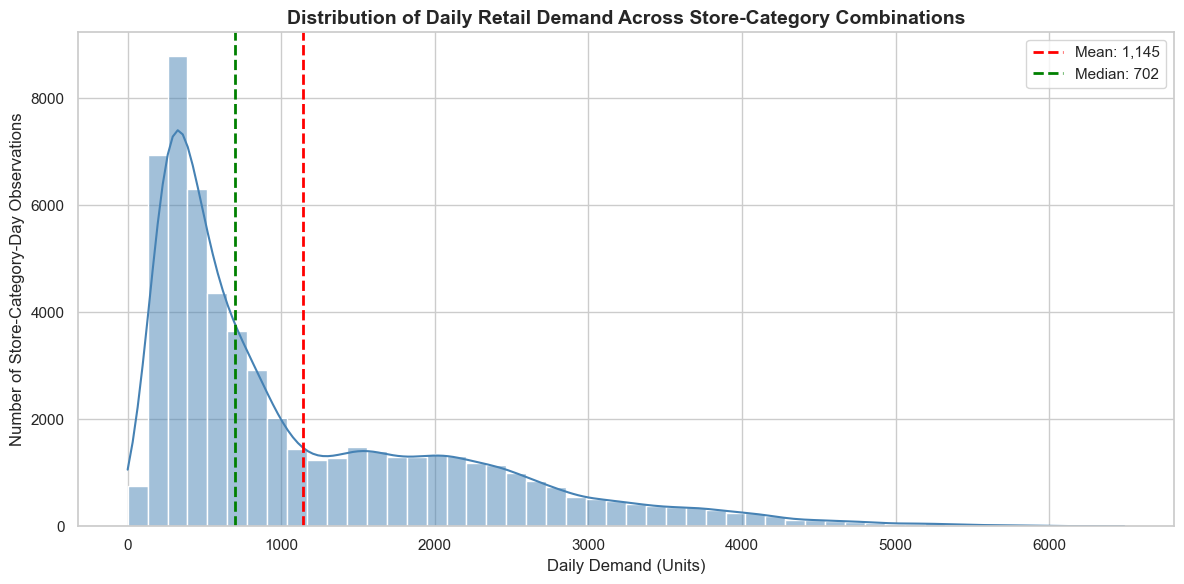

In [11]:
# 3.3 Visualize the distribution of daily retail demand

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="demand",
    bins=50,
    kde=True,
    color="steelblue",
    edgecolor="white"
)

# Add mean and median reference lines
plt.axvline(
    overall_avg_demand,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {overall_avg_demand:,.0f}"
)

plt.axvline(
    overall_median_demand,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: {overall_median_demand:,.0f}"
)

plt.title(
    "Distribution of Daily Retail Demand Across Store-Category Combinations",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Daily Demand (Units)")
plt.ylabel("Number of Store-Category-Day Observations")

plt.legend()
plt.tight_layout()
plt.show()

### 3.4 — Interpretation of Overall Retail Demand

**Research Question:** What are the typical demand levels, variability, and distribution of daily retail demand across Walmart's store-category combinations?

The descriptive statistics and demand distribution reveal several important characteristics of Walmart's historical retail demand.

**1. Typical demand levels**

The dataset records approximately **65.70 million units of total demand** over the observation period. Average daily demand per store-category combination is **1,144.72 units**, compared with a median of **702 units**.

**2. Demand variability**

Daily demand ranges from **0 to 6,488 units**, with a standard deviation of **1,049.79 units**. This substantial variation indicates that demand levels differ considerably across store-category-day observations.

**3. Demand distribution**

The histogram reveals a **positively skewed distribution**, with most observations concentrated at relatively low demand levels and a long right tail extending toward higher values.

The mean being considerably greater than the median supports this observation, suggesting that higher-demand observations influence the overall average.

**4. Implications for forecasting**

The findings suggest that demand is not uniformly distributed across Walmart's store-category combinations.

Forecasting models should therefore account for differences in demand scale and historical behavior. Store-category identifiers, lagged demand, and rolling demand statistics may help capture these differences.

**Conclusion:** Walmart's historical demand exhibits substantial variability and positive skewness, highlighting the importance of modeling demand patterns at the store-category level rather than relying exclusively on aggregate averages.

## Step 4 — Overall Demand Trend

**Research Question:** How has total daily retail demand evolved over time, and what trends and recurring patterns are visible?

This analysis examines historical retail demand by aggregating daily sales quantities across all Walmart stores and product categories.

Visualizing total daily demand over the observation period allows us to investigate long-term movements, short-term fluctuations, and potential recurring seasonal patterns.

Understanding these temporal characteristics helps guide the selection of forecasting approaches and time-dependent features.

In [13]:
# 4.1 Aggregate demand across all stores and categories by day

daily_demand = (
    df.groupby("date", as_index=False)["demand"]
      .sum()
      .sort_values("date")
)

print("Daily demand shape:", daily_demand.shape)
display(daily_demand.head())

Daily demand shape: (1913, 2)


,date,demand
0,2011-01-29,32631
1,2011-01-30,31749
2,2011-01-31,23783
3,2011-02-01,25412
4,2011-02-02,19146


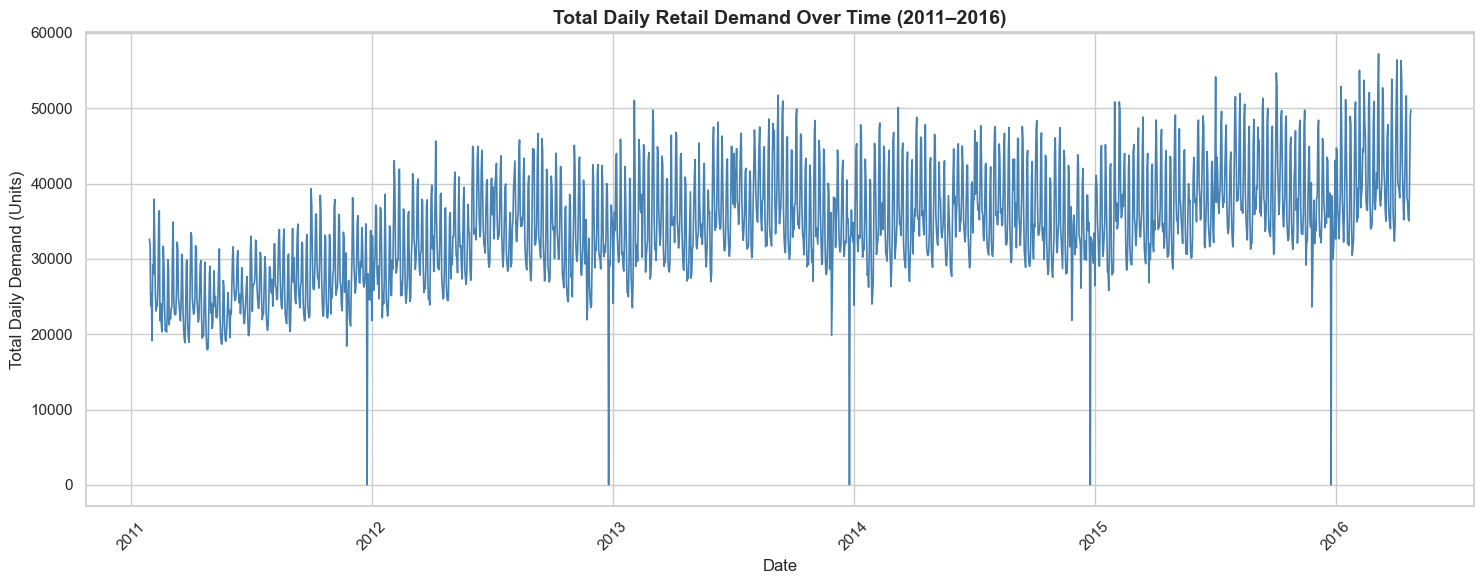

In [14]:
# 4.2 Plot total daily demand over time

# 4.2 Plot total daily demand over time

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=daily_demand,
    x="date",
    y="demand",
    color="steelblue",
    linewidth=1.2
)

plt.title(
    "Total Daily Retail Demand Over Time (2011–2016)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Total Daily Demand (Units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation

The overall demand time series shows an increasing trend over the observed period, with total daily demand generally higher in later years than at the beginning of the dataset.

The series also exhibits substantial short-term fluctuations and recurring patterns, suggesting the presence of seasonality. In particular, the regular variation between consecutive days indicates that weekly demand patterns may be important for forecasting.

Several sharp decreases in demand are also visible in the series. These observations are retained because the data-quality checks found no negative demand values, duplicate store-category-day observations, or missing dates. Their underlying patterns will be investigated further during the time-series analysis.

The demand distribution is *positively skewed,* with a mean demand of approximately **1,145 units** per store-category-day compared with a median of **702 units.** The relatively large standard deviation also indicates considerable variation in demand across stores, categories, and days.

These findings suggest that a forecasting model should account for both long-term trends and recurring seasonal patterns rather than relying only on historical average demand.

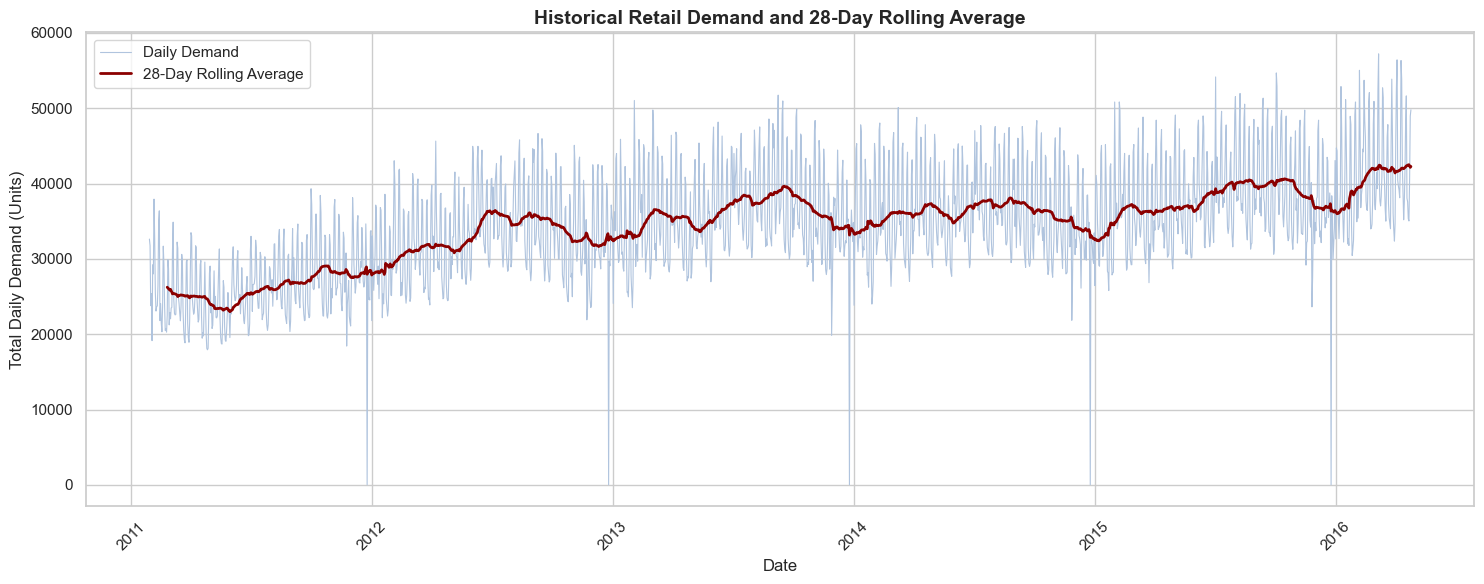

In [15]:
# 4.3 Calculate and visualize the 28-day rolling average

daily_demand["rolling_mean_28"] = (
    daily_demand["demand"]
    .rolling(window=28, min_periods=28)
    .mean()
)

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=daily_demand,
    x="date",
    y="demand",
    color="lightsteelblue",
    linewidth=0.8,
    label="Daily Demand"
)

sns.lineplot(
    data=daily_demand,
    x="date",
    y="rolling_mean_28",
    color="darkred",
    linewidth=2,
    label="28-Day Rolling Average"
)

plt.title(
    "Historical Retail Demand and 28-Day Rolling Average",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Total Daily Demand (Units)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### 4.4 — Interpretation of Historical Retail Demand Trends

**Research Question:** How has total daily retail demand evolved over time, and what trends and recurring patterns are visible?

The historical time series and 28-day rolling average reveal several important characteristics of Walmart's retail demand between January 2011 and April 2016.

**1. Long-term upward trend**

Total daily demand generally increased over the observation period. The 28-day rolling average rose from approximately 25,000–26,000 units in early 2011 to around 42,000 units by April 2016.

This indicates substantial growth in aggregate demand, although the increase was not uniform throughout the period.

**2. Short-term demand fluctuations**

Daily demand exhibits frequent peaks and troughs around the rolling average. These fluctuations suggest recurring short-term patterns that may be associated with weekday purchasing behavior or other calendar-related factors.

**3. Periods of growth and decline**

The smoothed trend shows periods of increasing demand alongside temporary declines and relatively stable intervals. This indicates that the underlying demand trend changes over time rather than following a constant growth rate.

**4. Recurring extreme declines**

The daily demand series contains unusually sharp declines near the end of several calendar years. These observations warrant further investigation using the dataset's holiday and event information to determine whether they are associated with specific calendar events.

**5. Implications for forecasting**

The observed trends and fluctuations support the inclusion of time-dependent predictors such as lagged demand, rolling averages, calendar variables, and seasonal indicators.

However, the aggregate demand trend does not necessarily describe every individual store-category series. Further analysis at more granular levels is therefore necessary.

**Conclusion:** Walmart's historical retail demand exhibits an overall upward trend, substantial short-term fluctuations, and potentially recurring calendar-related patterns. Forecasting approaches should account for both longer-term movements and shorter-term demand dynamics.

## Step 5 — Weekly Seasonality

**Research Question:** How does average daily retail demand vary across the days of the week, and what weekly seasonal patterns are present?


Retail demand can vary systematically across days of the week. Customers may purchase different quantities on weekdays and weekends, creating a recurring weekly pattern.

Because the dataset contains daily observations over more than five years, we can compare average demand across the seven days of the week.

Identifying a consistent weekly pattern will help determine whether weekly seasonal features and lagged demand should be included in the forecasting model.

In [16]:
# 5.1 Calculate average demand for each day of the week

weekday_demand = (
    df.groupby(["weekday_num", "weekday"])["demand"]
      .mean()
      .reset_index()
      .sort_values("weekday_num")
)

weekday_demand

,weekday_num,weekday,demand
0,1,Saturday,1384.896472
1,2,Sunday,1371.000730
2,3,Monday,1095.098901
3,4,Tuesday,1012.292674
4,5,Wednesday,1000.334066
5,6,Thursday,1006.833578
6,7,Friday,1140.866178


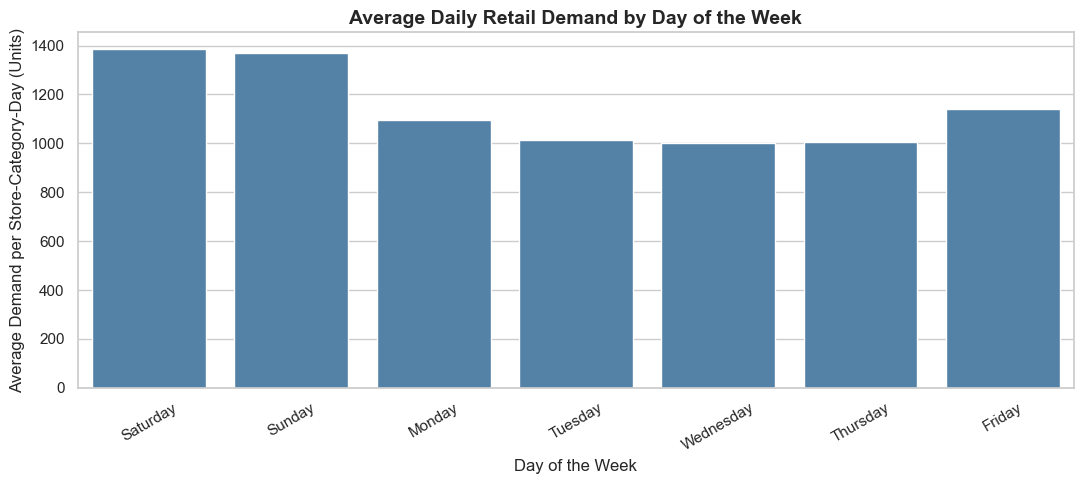

In [19]:
# 5.2 Visualize average demand by day of the week

plt.figure(figsize=(11, 5))

sns.barplot(
    data=weekday_demand,
    x="weekday",
    y="demand",
    color="steelblue"
)

plt.title(
    "Average Daily Retail Demand by Day of the Week",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Day of the Week")
plt.ylabel("Average Demand per Store-Category-Day (Units)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [20]:
# 5.3 Identify the days with the highest and lowest average demand

highest_day = weekday_demand.loc[
    weekday_demand["demand"].idxmax()
]

lowest_day = weekday_demand.loc[
    weekday_demand["demand"].idxmin()
]

print(
    "Highest average demand:",
    highest_day["weekday"],
    f"({highest_day['demand']:.2f})"
)

print(
    "Lowest average demand:",
    lowest_day["weekday"],
    f"({lowest_day['demand']:.2f})"
)

Highest average demand: Saturday (1384.90)
Lowest average demand: Wednesday (1000.33)


### 5.4 — Interpretation of Weekly Seasonality

The analysis reveals a clear weekly pattern in Walmart's historical retail demand.

**1. Weekend demand peaks**

Saturday records the highest average daily demand at **1,384.90 units**, followed closely by Sunday at **1,371.00 units**. This suggests that weekend shopping activity is associated with higher demand.

**2. Lower midweek demand**

Wednesday has the lowest average demand at **1,000.33 units**, followed by Thursday and Tuesday. Saturday's average demand is approximately **38.4% higher than Wednesday's**, indicating a substantial difference between peak and low-demand days.

**3. Weekly demand pattern**

Demand generally increases toward the weekend and decreases during the middle of the week. This recurring variation provides evidence of weekly seasonality in the aggregated store-category observations.

**4. Implications for forecasting**

The observed weekly pattern supports incorporating day-of-week indicators, cyclical weekday encodings, and relevant historical demand lags into forecasting models.

However, the strength of weekly seasonality may differ across individual stores and product categories, which should be considered in subsequent analysis.

**Conclusion:** Walmart's retail demand exhibits a pronounced weekly pattern, with stronger demand during weekends and comparatively lower demand during the middle of the week. Accounting for weekly seasonality is important for accurate daily demand forecasting.

### Weekly Seasonality — Key Finding

The analysis reveals a clear weekly seasonal pattern in retail demand. Average demand is highest on Saturday (1,384.90 units) and Sunday (1,371.00 units), while the lowest average demand occurs on Wednesday (1,000.33 units).

Saturday demand is approximately 38.4% higher than Wednesday demand, indicating that the day of the week is an important factor in explaining retail demand variation.

This recurring weekly pattern provides evidence that temporal features such as the day of the week, as well as lagged demand from previous weeks, may be useful predictors in the forecasting model. The finding also supports the use of a weekly seasonal-naive baseline in the machine-learning phase.

The analysis identifies a strong relationship between the calendar day and demand, although the underlying behavioral reasons for this pattern are not established by this analysis alone.

## Step 6 — Monthly and Yearly Seasonality

### Research Question

**How does Walmart's retail demand vary across months and years, and what longer-term seasonal patterns can be identified?**

### Objective

The weekly seasonality analysis revealed substantial differences in demand across days of the week, particularly between weekends and weekdays.

This section extends the analysis to investigate **monthly and yearly demand patterns**, examining whether certain months consistently experience higher or lower demand and how demand levels evolve across different years.

### Analytical Approach

Monthly and yearly demand patterns will be examined to:

- Identify months associated with relatively high or low average demand.
- Investigate recurring seasonal fluctuations throughout the year.
- Examine how overall demand changes across years.
- Distinguish potential seasonal patterns from longer-term demand growth.

### Relevance to Forecasting

Understanding monthly and yearly demand behavior is important for developing an accurate **28-day retail demand forecasting model**.

The findings will help determine whether calendar features such as `month`, `year`, and cyclical seasonal indicators should be included alongside weekly seasonality and historical demand features.

This analysis will also help assess whether demand patterns remain relatively stable or change over time.

In [26]:
# 6.1 Calculate average demand by month

monthly_demand = (
    df.groupby("month")["demand"]
      .mean()
      .reset_index()
)

# Percentage difference from overall average
monthly_demand["difference_from_overall_pct"] = (
    (monthly_demand["demand"] - overall_avg_demand)
    / overall_avg_demand
) * 100

monthly_demand

# Add month abbreviations while preserving the original month numbers
monthly_demand["month_name"] = monthly_demand["month"].apply(
    lambda x: calendar.month_abbr[x]
)

# Display the updated monthly summary
display(
    monthly_demand[
        ["month_name", "demand", "difference_from_overall_pct"]
    ]
)

,month_name,demand,difference_from_overall_pct
0,Jan,1127.744937,-1.482793
1,Feb,1154.821373,0.882542
2,Mar,1144.661290,-0.005019
3,Apr,1141.956130,-0.241336
4,May,1083.461720,-5.351273
5,Jun,1166.713778,1.921435
6,Jul,1170.747312,2.273795
7,Aug,1198.221505,4.673878
8,Sep,1182.642000,3.312888
9,Oct,1157.115914,1.082988


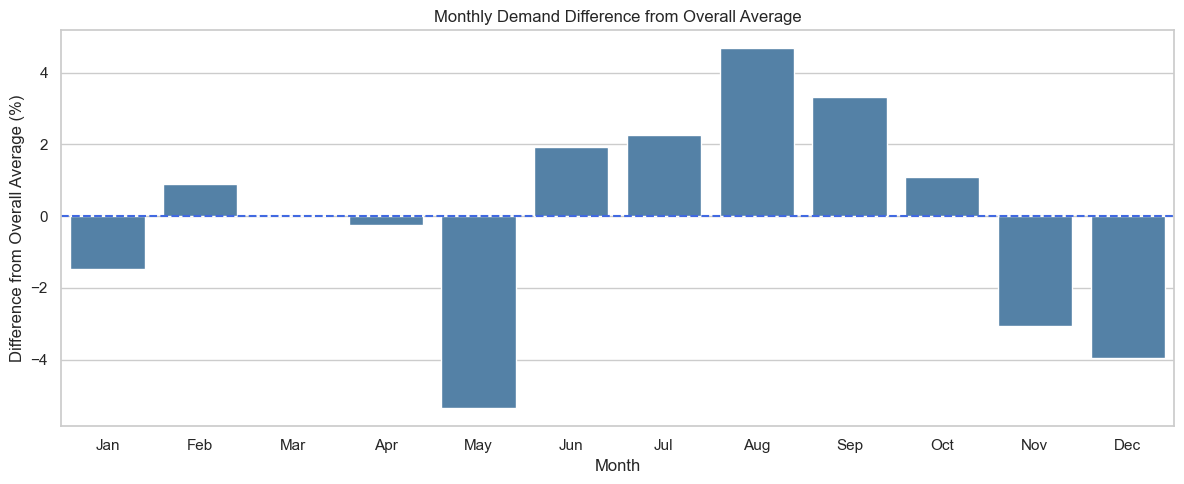

In [29]:
# 6.2 Monthly demand difference from overall average

plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_demand,
    x="month_name",
    y="difference_from_overall_pct",
    color="steelblue"
)

plt.axhline(
    y=0,
    color="royalblue",
    linestyle="--",
    linewidth=1.5
)

plt.title("Monthly Demand Difference from Overall Average")
plt.xlabel("Month")
plt.ylabel("Difference from Overall Average (%)")

plt.tight_layout()
plt.show()

This graph answer :

How far above or below the normal overall demand is each month?

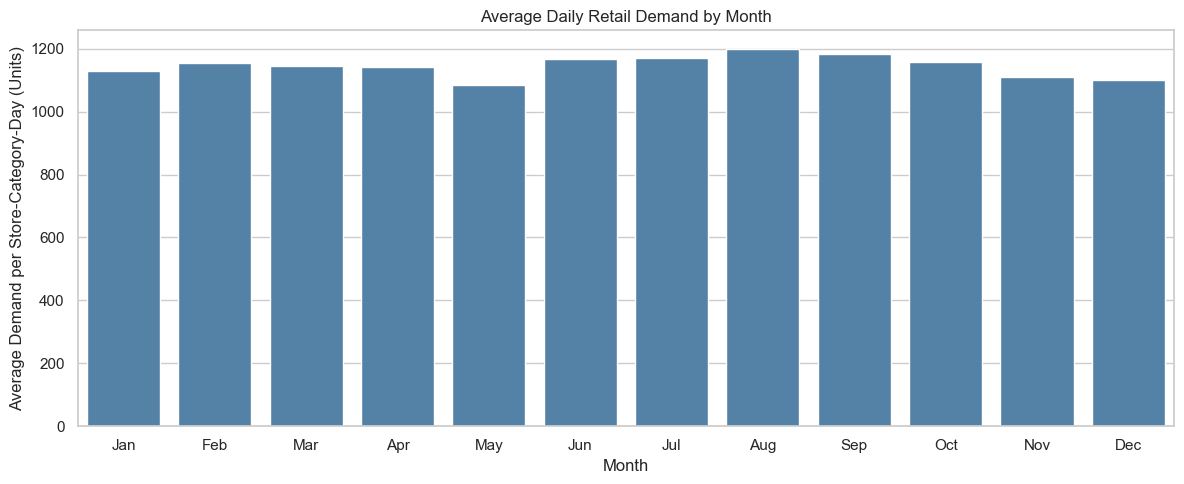

In [30]:
# 6.3 Average daily retail demand by month

plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_demand,
    x="month_name",
    y="demand",
    color="steelblue"
)

plt.title("Average Daily Retail Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Demand per Store-Category-Day (Units)")

plt.tight_layout()
plt.show()

This also answers:

"How much demand does each month have?

### Monthly Seasonality — Interpretation of Steps 6.1–6.3

**Research Question:** How does Walmart's retail demand vary across months and years, and what longer-term seasonal patterns can be identified?

The monthly analysis reveals moderate differences in average daily retail demand across calendar months.

**1. Months with the highest and lowest demand**

August records the highest average demand at **1,198.22 units per store-category-day**, approximately **4.67% above** the overall average of 1,144.72 units.

May records the lowest average demand at **1,083.46 units**, approximately **5.35% below** the overall average.

**2. Monthly demand differences**

Demand is above the overall average in February, June, July, August, September, and October, while other months are at or below the overall average.

The difference between August and May is approximately **10.59% relative to May**, indicating moderate variation in average demand across months.

**3. Comparison with weekly seasonality**

The observed monthly differences are smaller than the differences identified in the weekly analysis.

The highest-demand weekday, Saturday, has approximately **38.4% higher average demand than Wednesday**, while August has approximately **10.6% higher average demand than May**.

This suggests that weekly demand differences are more pronounced in the pooled historical data.

**4. Implications for forecasting**

Monthly demand differences support investigating calendar-month and annual seasonal features alongside the stronger weekly patterns.

However, because these averages combine observations from multiple years, they do not establish that the same monthly pattern repeats consistently every year. Further year-by-year analysis is necessary to distinguish recurring seasonality from changes in overall demand levels.

**Conclusion:** Walmart's historical retail demand exhibits moderate monthly variation, with August recording the highest average and May the lowest. These findings suggest that monthly calendar information may be useful for forecasting, but the consistency of annual seasonal patterns requires further examination.

AVERAGE 

In [31]:
# 6.4 Calculate average demand by year

yearly_demand = (
    df.groupby("year")["demand"]
      .mean()
      .reset_index()
)

# Calculate year-over-year percentage change

yearly_demand["year_over_year_pct"] = (
    yearly_demand["demand"].pct_change() * 100
)

yearly_demand

,year,demand,year_over_year_pct
0,2011,876.022255,NaN
1,2012,1098.527960,25.399549
2,2013,1199.612146,9.201785
3,2014,1195.413333,-0.350014
4,2015,1260.348037,5.431988
5,2016,1376.999130,9.255467


### Yearly Demand — Key Findings

The yearly analysis shows a clear long-term increase in average retail demand over the observed period.

Average demand increased from 876.02 units per store-category-day in 2011 to 1,260.35 units in 2015, representing an overall increase of approximately 43.9%.

The largest year-over-year increase occurred between 2011 and 2012, when average demand increased by 25.40%. Growth continued in 2013 at 9.20%, while demand remained relatively stable in 2014, changing by only -0.35%. Growth resumed in 2015, with average demand increasing by 5.43%.

The 2016 observation requires caution because the dataset ends on April 24, 2016. Therefore, the 2016 average is based only on a partial year and should not be directly compared with the full-year averages from 2011–2015.

Overall, the results indicate that the forecasting model should account for both recurring seasonality and longer-term changes in demand over time.

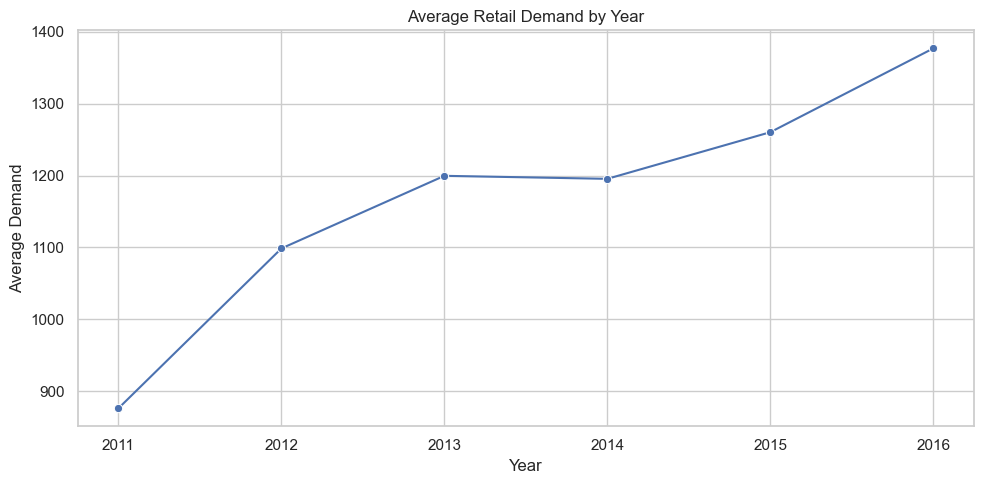

In [32]:
# 6.5 
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_demand,
    x="year",
    y="demand",
    marker="o"
)

plt.title("Average Retail Demand by Year")
plt.xlabel("Year")
plt.ylabel("Average Demand")

plt.tight_layout()
plt.show()

### 6.4 — Interpretation of Yearly Demand Trends

The yearly analysis shows an overall increase in average daily retail demand across Walmart's store-category combinations between 2011 and 2016.

**1. Overall demand growth**

Average daily demand increased from **876.02 units in 2011** to **1,377.00 units in 2016**. This indicates that demand levels were generally higher toward the end of the observation period.

**2. Year-over-year changes**

The analysis records a substantial increase of **25.40% in 2012**, followed by **9.20% growth in 2013**.

Demand remained relatively stable in 2014, declining slightly by **0.35%**, before increasing by **5.43% in 2015**.

The reported increase for 2016 is **9.26%**, although this comparison requires caution because 2016 contains only observations through April 24.

**3. Partial-year limitation**

The dataset begins on January 29, 2011, and ends on April 24, 2016. Consequently, 2011 and 2016 are incomplete calendar years, whereas 2012–2015 are complete.

Year-over-year comparisons involving incomplete years may be influenced by differences in seasonal coverage and should not be interpreted as fully comparable annual growth rates.

**4. Implications for forecasting**

The overall increase in demand supports incorporating features that capture changes over time, such as historical demand lags, rolling averages, and a chronological time index.

The temporary stabilization in 2014 also suggests that demand growth is not constant and that forecasting models should accommodate changing trends.

**Conclusion:** Walmart's average daily retail demand generally increased over the observation period, with some periods of stabilization. The analysis supports modeling longer-term demand changes while accounting for seasonal variation and incomplete calendar-year coverage.

In [33]:
# 6.6 Calculate each year's difference from the overall average demand

yearly_demand["difference_from_overall_pct"] = (
    (yearly_demand["demand"] - overall_avg_demand)
    / overall_avg_demand
) * 100

yearly_demand

,year,demand,year_over_year_pct,difference_from_overall_pct
0,2011,876.022255,NaN,-23.472708
1,2012,1098.527960,25.399549,-4.035121
2,2013,1199.612146,9.201785,4.795361
3,2014,1195.413333,-0.350014,4.428562
4,2015,1260.348037,5.431988,10.101109
5,2016,1376.999130,9.255467,20.291480


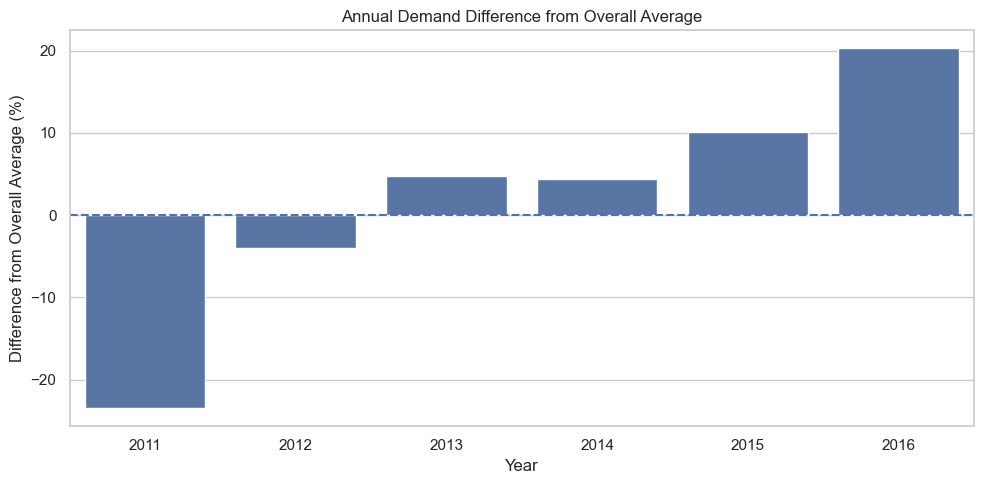

In [34]:
# 6.7 Visualize each year's difference from the overall average demand
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_demand,
    x="year",
    y="difference_from_overall_pct"
)

plt.axhline(0, linestyle="--")

plt.title("Annual Demand Difference from Overall Average")
plt.xlabel("Year")
plt.ylabel("Difference from Overall Average (%)")
plt.tight_layout()
plt.show()

In [36]:
# 6.8 Create monthly time-series demand

monthly_time_series = (
    df.groupby(pd.Grouper(key="date", freq="MS"))["demand"]
      .sum()
      .reset_index()
)

# Calculate month-over-month percentage change
monthly_time_series["month_over_month_pct"] = (
    monthly_time_series["demand"].pct_change() * 100
)

monthly_time_series.head()

,date,demand,month_over_month_pct
0,2011-01-01,88163,NaN
1,2011-02-01,726375,723.900049
2,2011-03-01,763567,5.120220
3,2011-04-01,737713,-3.385950
4,2011-05-01,719562,-2.460442


In [37]:
# 6.9 Create monthly time-series demand with observation counts

monthly_time_series = (
    df.groupby(pd.Grouper(key="date", freq="MS"))
      .agg(
          demand=("demand", "sum"),
          days_observed=("date", "nunique")
      )
      .reset_index()
)

# Extract year and month
monthly_time_series["year"] = monthly_time_series["date"].dt.year
monthly_time_series["month"] = monthly_time_series["date"].dt.month

# Calculate year-over-year percentage change for the same month
monthly_time_series["year_over_year_pct"] = (
    monthly_time_series
    .groupby("month")["demand"]
    .pct_change() * 100
)

monthly_time_series.head(15)

,date,demand,days_observed,year,month,year_over_year_pct
0,2011-01-01,88163,3,2011,1,NaN
1,2011-02-01,726375,28,2011,2,NaN
2,2011-03-01,763567,31,2011,3,NaN
3,2011-04-01,737713,30,2011,4,NaN
4,2011-05-01,719562,31,2011,5,NaN
5,2011-06-01,753380,30,2011,6,NaN
6,2011-07-01,819820,31,2011,7,NaN
7,2011-08-01,825694,31,2011,8,NaN
8,2011-09-01,813683,30,2011,9,NaN
9,2011-10-01,898243,31,2011,10,NaN


In [38]:
# 6.10 Count the number of observed days in each month
monthly_time_series[
    monthly_time_series["days_observed"] < 28
]

,date,demand,days_observed,year,month,year_over_year_pct
0,2011-01-01,88163,3,2011,1,NaN
63,2016-04-01,1046688,24,2016,4,-4.274717


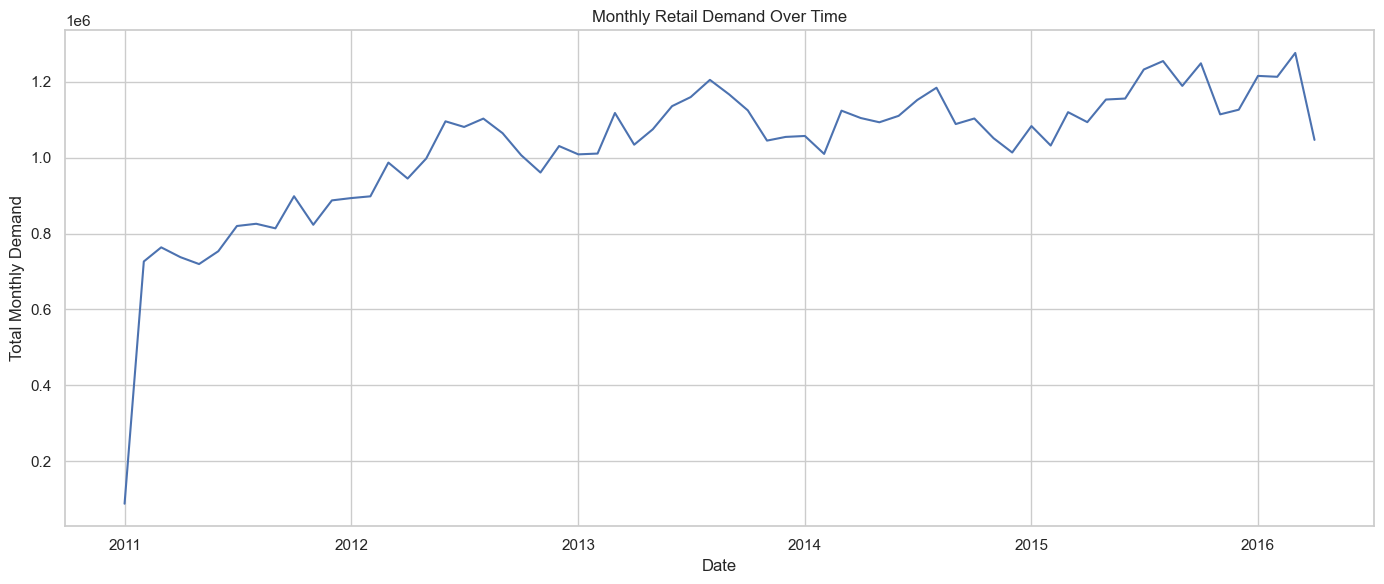

In [39]:
# 6.11 Visualize monthly total retail demand over time
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_time_series,
    x="date",
    y="demand"
)

plt.title("Monthly Retail Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Total Monthly Demand")
plt.tight_layout()
plt.show()

In [40]:
# 6.12 Identify complete months for year-over-year analysis

monthly_time_series["is_complete_month"] = (
    monthly_time_series["days_observed"]
    >= monthly_time_series["date"].dt.days_in_month
)

# Display incomplete months
monthly_time_series[
    ~monthly_time_series["is_complete_month"]
]

,date,demand,days_observed,year,month,year_over_year_pct,is_complete_month
0,2011-01-01,88163,3,2011,1,NaN,False
63,2016-04-01,1046688,24,2016,4,-4.274717,False


In [41]:
# 6.13 Calculate YoY percentage change using complete months only

complete_monthly = monthly_time_series[
    monthly_time_series["is_complete_month"]
].copy()

complete_monthly["year_over_year_pct"] = (
    complete_monthly
    .groupby("month")["demand"]
    .pct_change() * 100
)

complete_monthly.head(15)

,date,demand,days_observed,year,month,year_over_year_pct,is_complete_month
1,2011-02-01,726375,28,2011,2,NaN,True
2,2011-03-01,763567,31,2011,3,NaN,True
3,2011-04-01,737713,30,2011,4,NaN,True
4,2011-05-01,719562,31,2011,5,NaN,True
5,2011-06-01,753380,30,2011,6,NaN,True
6,2011-07-01,819820,31,2011,7,NaN,True
7,2011-08-01,825694,31,2011,8,NaN,True
8,2011-09-01,813683,30,2011,9,NaN,True
9,2011-10-01,898243,31,2011,10,NaN,True
10,2011-11-01,823087,30,2011,11,NaN,True


In [42]:
# 6.14 Find the largest positive and negative YoY changes
valid_yoy = complete_monthly.dropna(subset=["year_over_year_pct"])

highest_yoy = valid_yoy.loc[
    valid_yoy["year_over_year_pct"].idxmax()
]

lowest_yoy = valid_yoy.loc[
    valid_yoy["year_over_year_pct"].idxmin()
]

print(
    f"Largest YoY increase: "
    f"{highest_yoy['date'].strftime('%B %Y')} "
    f"({highest_yoy['year_over_year_pct']:.2f}%)"
)

print(
    f"Largest YoY decrease: "
    f"{lowest_yoy['date'].strftime('%B %Y')} "
    f"({lowest_yoy['year_over_year_pct']:.2f}%)"
)

Largest YoY increase: June 2012 (45.43%)
Largest YoY decrease: September 2014 (-6.70%)


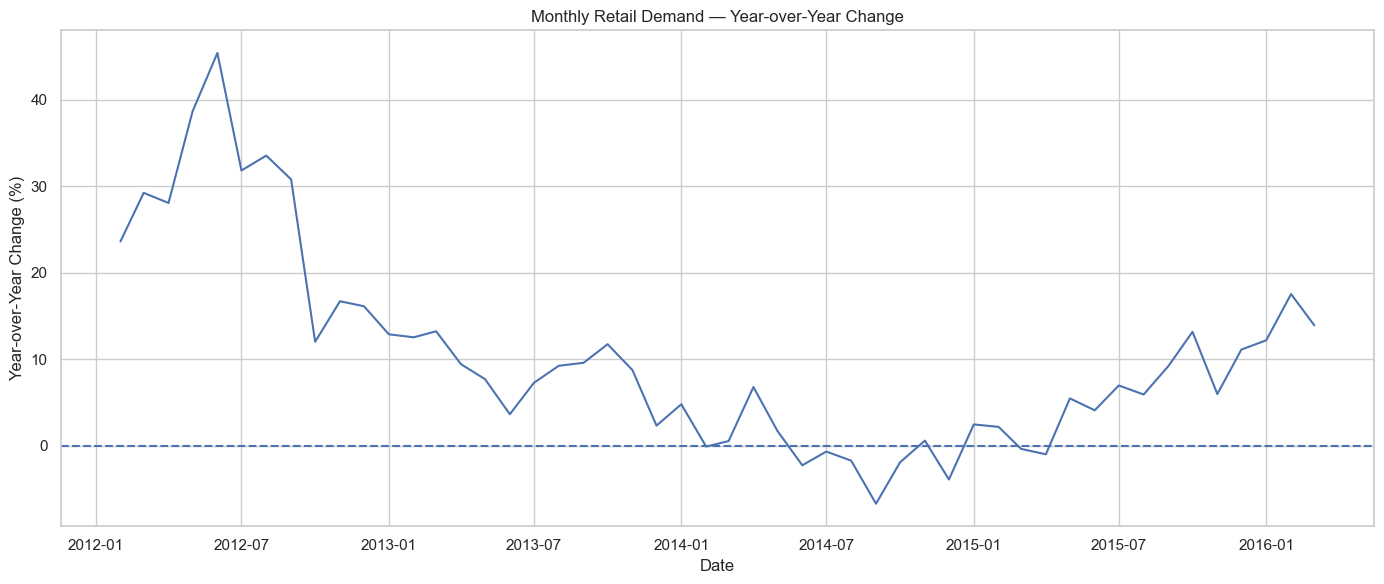

In [43]:
# 6.15 Visualize YoY percentage change over time
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=complete_monthly,
    x="date",
    y="year_over_year_pct"
)

plt.axhline(0, linestyle="--")

plt.title("Monthly Retail Demand — Year-over-Year Change")
plt.xlabel("Date")
plt.ylabel("Year-over-Year Change (%)")
plt.tight_layout()
plt.show()

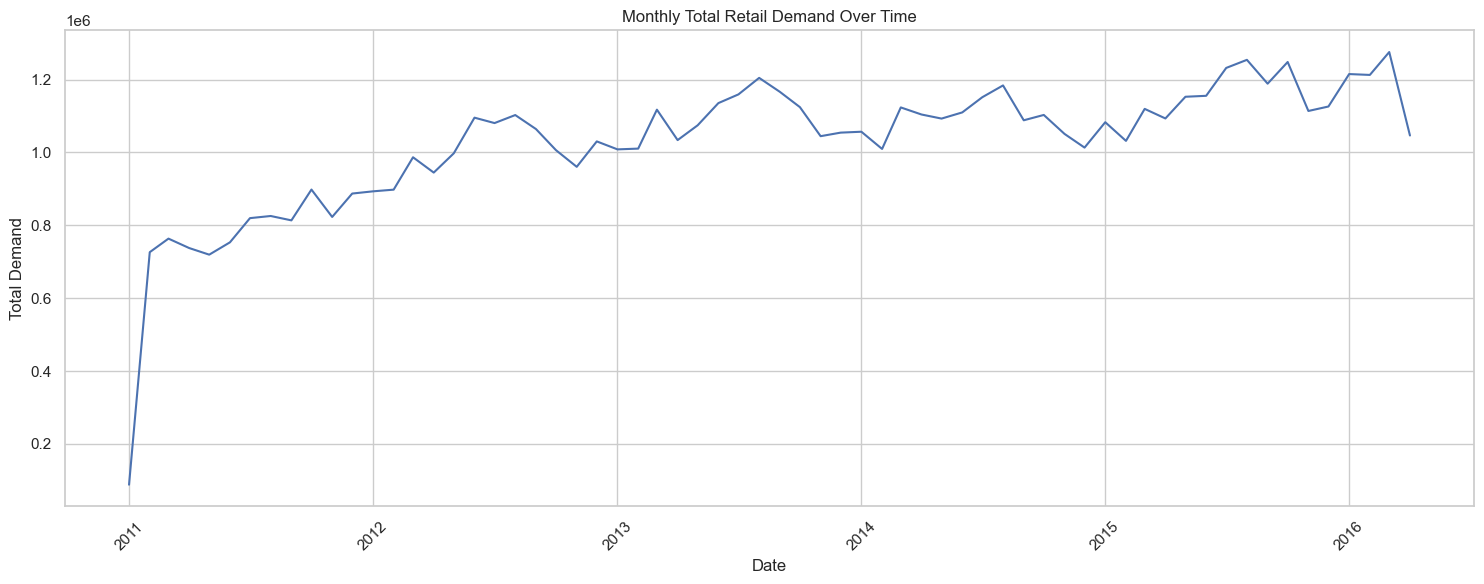

In [44]:
# 6.16 Visualize monthly total retail demand over time
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_time_series,
    x="date",
    y="demand"
)

plt.title("Monthly Total Retail Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Total Demand")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

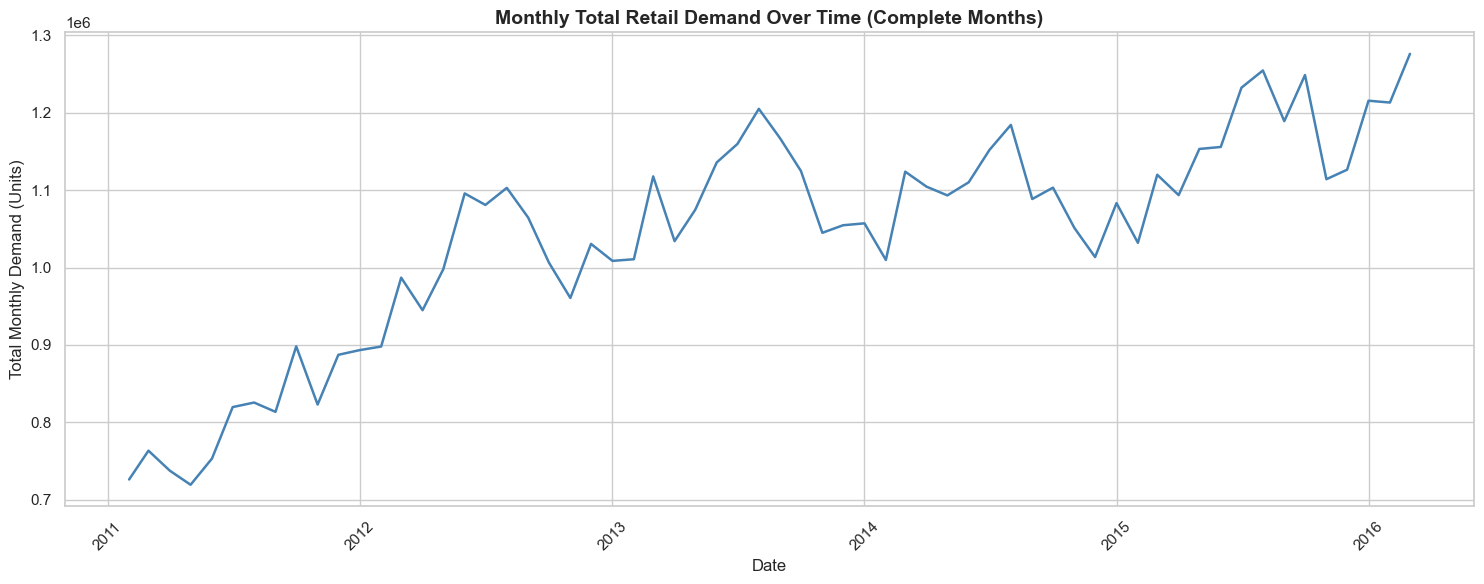

In [45]:
# 6.16 Visualize monthly total demand using complete months

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=complete_monthly,
    x="date",
    y="demand",
    color="steelblue",
    linewidth=1.8
)

plt.title(
    "Monthly Total Retail Demand Over Time (Complete Months)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Total Monthly Demand (Units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 6 — Overall Interpretation and Forecasting Implications

**Research Question:** How does Walmart's retail demand vary across months and years, and what longer-term seasonal patterns can be identified?

The monthly and yearly analyses reveal moderate differences across calendar months, a generally increasing demand trend, and varying rates of year-over-year growth.

**1. Monthly demand patterns**

August records the highest average daily demand at **1,198.22 units per store-category-day**, approximately **4.67% above** the overall average.

May records the lowest average at **1,083.46 units**, approximately **5.35% below** the overall average.

The difference between these monthly averages is approximately **10.59% relative to May**, indicating moderate monthly variation compared with the stronger weekly demand differences identified in Step 5.

**2. Yearly demand trends**

Average daily demand generally increased from 2011 to 2016, although growth was not uniform.

The complete calendar years show an increase from **1,098.53 units in 2012** to **1,260.35 units in 2015**, with a slight decline in 2014.

The 2011 and 2016 yearly averages should be interpreted cautiously because they represent incomplete calendar years.

**3. Monthly demand growth**

The complete-month time series confirms a general upward movement in total monthly demand, alongside temporary declines and periods of stabilization.

Among valid year-over-year comparisons, the largest increase occurred in **June 2012 (+45.43%)**, while the largest decrease occurred in **September 2014 (−6.70%)**.

These results indicate that demand growth varies over time.

**4. Data completeness and analytical reliability**

January 2011 contains only three observed days, and April 2016 contains 24 observed days.

These incomplete months were excluded from the final complete-month comparisons to avoid misleading differences caused by unequal observation periods.

All original observations remain available for subsequent daily forecasting analysis.

**5. Implications for forecasting**

The findings support incorporating monthly calendar information, historical demand lags, rolling statistics, and features representing changes in demand over time.

Weekly seasonality remains particularly important, while the monthly and yearly analyses suggest that longer-term temporal patterns may also contribute useful predictive information.

The consistency of monthly seasonal effects across individual years and store-category combinations should be assessed before treating them as stable recurring patterns.

**Conclusion:** Walmart's historical retail demand demonstrates moderate monthly variation, an overall upward trend, and changing year-over-year growth rates. Forecasting models should account for both recurring calendar effects and evolving demand levels to support accurate 28-day predictions.

### Monthly Time-Series — Key Findings

The monthly time-series analysis shows that total retail demand generally increased over the observed period, while also exhibiting substantial month-to-month variation.

The year-over-year analysis provides a more meaningful percentage comparison by comparing each month with the same month in the previous year. Incomplete boundary months were excluded from this calculation because January 2011 contains only three observed days and April 2016 contains only 24 observed days.

Among the valid complete-month comparisons, the largest year-over-year increase occurred in June 2012, with demand increasing by approximately 45.43% compared with June 2011. The largest year-over-year decrease occurred in September 2014, with demand decreasing by approximately 6.70% compared with September 2013.

The combination of the absolute demand trend and the year-over-year percentage analysis indicates that retail demand is influenced by both longer-term changes and recurring seasonal patterns.

These findings reinforce the need for the forecasting model to incorporate temporal information rather than relying only on historical average demand.

### Monthly and Yearly Seasonality — Key Findings

The monthly analysis shows moderate seasonal variation in retail demand. Average demand is highest in August at approximately 1,198 units per store-category-day and lowest in May at approximately 1,083 units. This represents a difference of approximately 10.6%, suggesting that monthly seasonality exists but is less pronounced than the weekly pattern identified previously.

The yearly analysis reveals a stronger long-term change in demand. Average demand increased from approximately 876 units in 2011 to approximately 1,260 units in 2015, representing an increase of roughly 44%. This indicates that the demand series contains an important long-term trend in addition to its recurring seasonal patterns.

The 2016 average is approximately 1,377 units; however, the 2016 data is incomplete because the available historical sales data ends on April 24, 2016. Therefore, the 2016 average should not be directly compared with the full-year averages of previous years.

Overall, the analysis indicates that retail demand contains multiple temporal components: strong weekly seasonality, moderate monthly seasonality, and a longer-term upward trend. These patterns should be considered when developing the forecasting model.

## Step 7 — Demand by State

### Research Question

**How does Walmart's retail demand differ across California, Texas, and Wisconsin in terms of average daily demand and total sales volume?**

### Objective

Retail demand may vary across geographical markets due to differences in customer purchasing behavior, store characteristics, and regional demand patterns.

The M5 Walmart dataset includes stores operating in three U.S. states: **California (CA), Texas (TX), and Wisconsin (WI)**.

This section examines geographical differences in retail demand to understand how demand levels and overall sales volumes vary across these markets.

### Analytical Approach

State-level demand will be analyzed using two complementary measures:

- **Average Daily Demand:** Measures the average number of units sold per store-category-day, allowing comparisons across states with different numbers of stores.
- **Total Demand:** Measures the total number of units sold in each state throughout the observation period, highlighting each state's contribution to overall retail demand.

An important consideration is that **California contains four stores**, while **Texas and Wisconsin each contain three stores**. Consequently, differences in total demand may partly reflect the number of stores represented in each state rather than differences in demand intensity alone.

Both measures will therefore be considered together to provide a balanced interpretation of geographical demand patterns.

### Relevance to Forecasting

Identifying geographical differences can help determine whether location-related features, such as `state_id` and `store_id`, are important predictors of retail demand.

If demand patterns differ substantially across states, forecasting models may benefit from incorporating geographical information alongside historical demand, seasonality, and pricing features.

The findings will also help assess whether a single forecasting approach can capture demand behavior across different markets or whether location-specific patterns require additional consideration.

In [46]:
# 7.1 Calculate state-level demand
state_demand = (
    df.groupby("state_id")["demand"]
      .agg(["mean", "sum", "median"])
      .reset_index()
      .sort_values("mean", ascending=False)
)

state_demand

,state_id,mean,sum,median
0,CA,1249.152596,28675547,745.0
1,TX,1097.694488,18899006,750.0
2,WI,1052.497880,18120856,613.0


### State-Level Demand — Key Findings

**Research Question:** How does Walmart's retail demand differ across California, Texas, and Wisconsin in terms of average daily demand and total sales volume?

The state-level analysis reveals noticeable differences in retail demand across California (CA), Texas (TX), and Wisconsin (WI).

**1. Average daily demand**

California records the highest average demand at **1,249.15 units per store-category-day**, approximately **9.1% above** the overall dataset average of 1,144.72 units.

Texas follows with **1,097.69 units**, approximately **4.1% below** the overall average, while Wisconsin records the lowest average at **1,052.50 units**, approximately **8.1% below** the overall average.

**2. Total demand contribution**

California accounts for approximately **43.6%** of total observed demand, followed by Texas at **28.8%** and Wisconsin at **27.6%**.

However, California contains four stores, whereas Texas and Wisconsin each contain three. Consequently, differences in total demand partly reflect differences in store coverage.

Average demand per store-category-day provides a more comparable measure of demand intensity across states.

**3. Median demand**

Texas records the highest median demand at **750 units**, slightly above California's **745 units**. Wisconsin has the lowest median at **613 units**.

The difference between the average and median rankings suggests that state-level demand distributions are not identical and that higher-demand observations may influence the state averages differently.

**4. Implications for forecasting**

These differences suggest that geographical information, particularly `state_id` and `store_id`, may help forecasting models distinguish demand patterns across markets.

However, these findings are descriptive and do not establish that geographical location directly causes differences in demand.

**Conclusion:** California contributes the largest total demand and records the highest average demand, while Texas has a marginally higher median. State-level differences support considering geographical features when developing store-category-level demand forecasting models.

## 7.2 Percentage Share of Total Demand by State

To complement the average and total demand figures, we calculate the percentage share of total demand contributed by each state.

This shows how much of the overall observed retail demand comes from California, Texas, and Wisconsin.

Because the number of stores differs across states, this percentage should be interpreted as a measure of each state's contribution to total demand rather than as a direct measure of demand intensity.

In [47]:
# 7.2 Calculate total demand by state
state_total = (
    df.groupby("state_id")["demand"]
      .sum()
      .reset_index()
      .sort_values("demand", ascending=False)
)

# Calculate each state's percentage share of total demand
state_total["demand_share_pct"] = (
    state_total["demand"] / state_total["demand"].sum()
) * 100

state_total

,state_id,demand,demand_share_pct
0,CA,28675547,43.649240
1,TX,18899006,28.767621
2,WI,18120856,27.583139


### 7.2 — Percentage Share of Total Demand by State

This analysis examines each state's contribution to Walmart's total observed retail demand.

California contributes the largest share at **43.65%**, followed by Texas (**28.77%**) and Wisconsin (**27.58%**).

However, California has four stores, compared with three each in Texas and Wisconsin. Therefore, its larger demand share partly reflects greater store coverage rather than necessarily higher demand intensity.

**Forecasting implication:** State-level differences reinforce the importance of including geographical information when modeling demand across Walmart's stores.

## 7.3 Average Retail Demand by State

The following visualization compares the average retail demand per store-category-day across the three states.

Using average demand allows us to compare demand levels without the total being directly driven by the different number of stores in each state.

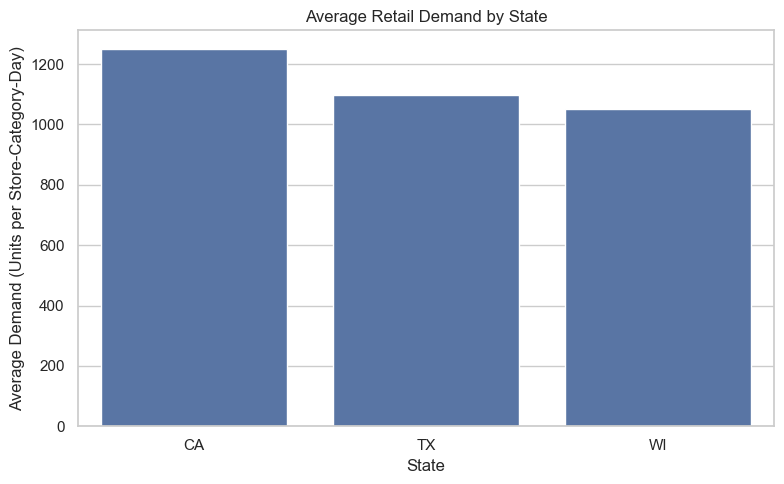

In [49]:
# 7.3 Create a bar chart of average demand by state

plt.figure(figsize=(8, 5))

sns.barplot(
    data=state_demand,
    x="state_id",
    y="mean"
)

plt.title("Average Retail Demand by State")
plt.xlabel("State")
plt.ylabel("Average Demand (Units per Store-Category-Day)")
plt.tight_layout()
plt.show()

### 7.3 — Average Retail Demand by State

This visualization compares average daily demand per store-category across California, Texas, and Wisconsin.

California records the highest average demand (**1,249.15 units**), approximately **13.8% higher than Texas** and **18.7% higher than Wisconsin**.

Unlike total demand, the average per store-category-day accounts for differences in store counts, providing a more comparable measure of demand intensity across states.

These variations suggest that geographical features may help forecasting models capture differences in demand levels across markets.

## 7.4 Relative Demand by State

To provide a relative comparison, the average demand for each state is compared with the overall average demand across all store-category-day observations.

This percentage shows whether each state's average demand is above or below the overall dataset average.

A positive percentage indicates demand above the overall average, while a negative percentage indicates demand below the overall average.

In [50]:
# 7.4 Calculate each state's difference from the overall average demand

state_demand["difference_from_overall_pct"] = (
    (state_demand["mean"] - overall_avg_demand)
    / overall_avg_demand
) * 100

state_demand

,state_id,mean,sum,median,difference_from_overall_pct
0,CA,1249.152596,28675547,745.0,9.123101
1,TX,1097.694488,18899006,750.0,-4.107931
2,WI,1052.497880,18120856,613.0,-8.056203


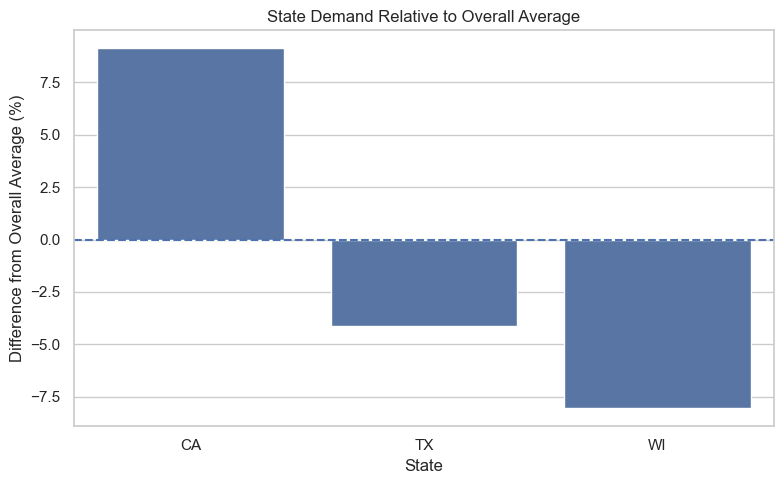

In [51]:
# 7.5 Plot demand relative to the overall average

plt.figure(figsize=(8, 5))

sns.barplot(
    data=state_demand,
    x="state_id",
    y="difference_from_overall_pct"
)

plt.axhline(0, linestyle="--")

plt.title("State Demand Relative to Overall Average")
plt.xlabel("State")
plt.ylabel("Difference from Overall Average (%)")

plt.tight_layout()
plt.show()

### State-Level Demand — Key Findings

The state-level analysis reveals noticeable differences in retail demand across California (CA), Texas (TX), and Wisconsin (WI).

California has the highest average demand at approximately 1,249.15 units per store-category-day. This is 9.12% above the overall dataset average of 1,144.72 units. Texas has an average demand of approximately 1,097.69 units, which is 4.11% below the overall average, while Wisconsin records approximately 1,052.50 units, or 8.06% below the overall average.

California also contributes the largest share of total observed demand, accounting for 43.65% of total demand. Texas contributes 28.77%, while Wisconsin contributes 27.58%.

However, total demand must be interpreted together with store coverage. California contains four stores, whereas Texas and Wisconsin each contain three stores. Therefore, California's larger share of total demand is partly influenced by its greater number of stores. Average demand provides a more appropriate measure when comparing demand intensity across states.

The differences between states suggest that geographic information may provide useful predictive information for the forecasting model. Nevertheless, these results are descriptive and do not establish that state location itself causes differences in demand.

Overall, the analysis indicates that demand varies across geographic markets, supporting the inclusion of store and state information as potential features in the forecasting stage.

The zero-reference line highlights these differences, confirming that California has the highest relative demand intensity.

Forecasting implication: These variations suggest that including state_id and store_id may help models capture geographical differences in baseline demand.

## 8.1 Store-Level Demand

The first step is to calculate demand statistics for each individual store.

We calculate the mean, total, and median demand for each store. The mean demand allows us to compare the typical demand level across stores, while total demand shows each store's overall contribution to observed demand. The median provides an additional measure of typical demand that is less affected by unusually high demand observations.

### 8.1 — Store-Level Demand

**Research Question:** How does retail demand vary across Walmart's 10 stores in terms of average, total, and median demand?

This analysis compares demand across individual stores using three measures:

- **Mean demand:** Average units sold per store-category-day, enabling comparisons across stores.
- **Total demand:** Cumulative units sold, indicating each store's contribution to overall demand.
- **Median demand:** Typical demand level, less influenced by unusually high observations.

**Forecasting relevance:** Store-level differences may indicate the importance of including `store_id` as a predictive feature to capture location-specific demand patterns.

In [52]:
# 8.1 Calculate demand statistics for each store

store_demand = (
    df.groupby("store_id")["demand"]
      .agg(["mean", "sum", "median"])
      .reset_index()
      .sort_values("mean", ascending=False)
)

store_demand

,store_id,mean,sum,median
2,CA_3,1949.499913,11188180,1433.0
0,CA_1,1341.386304,7698216,737.0
5,TX_2,1257.080328,7214384,796.0
8,WI_2,1140.270430,6544012,735.0
9,WI_3,1120.017773,6427782,619.0
6,TX_3,1061.043736,6089330,730.0
1,CA_2,990.673462,5685475,757.0
4,TX_1,974.959401,5595292,714.0
7,WI_1,897.205436,5149062,545.0
3,CA_4,715.050706,4103676,409.0


### Store-Level Demand — Key Findings

Store-level demand varies substantially across Walmart's 10 stores.

**CA_3** records the highest average demand (**1,949.50 units per store-category-day**), while **CA_4** records the lowest (**715.05 units**), representing a **2.73-fold difference** within California.

CA_3 also contributes the highest total demand (**11.19 million units**) and has the highest median (**1,433 units**).

These findings indicate that demand differences exist not only between states but also between stores within the same state.

**Forecasting implication:** Including `store_id` alongside `state_id` may help machine-learning models capture store-specific demand patterns that broader geographical features cannot fully explain.

## 8.2 Percentage Share of Total Demand by Store

To complement the store-level demand statistics, we calculate the percentage share of total demand contributed by each store.

This measure shows the relative contribution of each store to the overall demand observed in the dataset.

In [53]:
# 8.2 Calculate each store's percentage share of total demand

store_demand["demand_share_pct"] = (
    store_demand["sum"] / store_demand["sum"].sum()
) * 100

store_demand

,store_id,mean,sum,median,demand_share_pct
2,CA_3,1949.499913,11188180,1433.0,17.030383
0,CA_1,1341.386304,7698216,737.0,11.718043
5,TX_2,1257.080328,7214384,796.0,10.981565
8,WI_2,1140.270430,6544012,735.0,9.961141
9,WI_3,1120.017773,6427782,619.0,9.784218
6,TX_3,1061.043736,6089330,730.0,9.269034
1,CA_2,990.673462,5685475,757.0,8.654296
4,TX_1,974.959401,5595292,714.0,8.517021
7,WI_1,897.205436,5149062,545.0,7.837781
3,CA_4,715.050706,4103676,409.0,6.246519


### 8.2 — Percentage Share of Total Demand by Store

This analysis measures each store's percentage contribution to Walmart's total observed retail demand.

**CA_3** contributes the largest share (**17.03%**), followed by **CA_1 (11.72%)** and **TX_2 (10.98%)**. In contrast, **CA_4** contributes the smallest share (**6.25%**).

CA_3 accounts for approximately **2.73 times** the demand of CA_4, highlighting substantial differences in sales volume even within the same state.

**Forecasting implication:** These variations reinforce the potential importance of store-specific features when predicting retail demand.

## 8.3 Average Retail Demand by Store

The following visualization compares average demand across the ten stores in the dataset.

Average demand is used to compare the typical demand level of each store independently of its total contribution to the dataset.

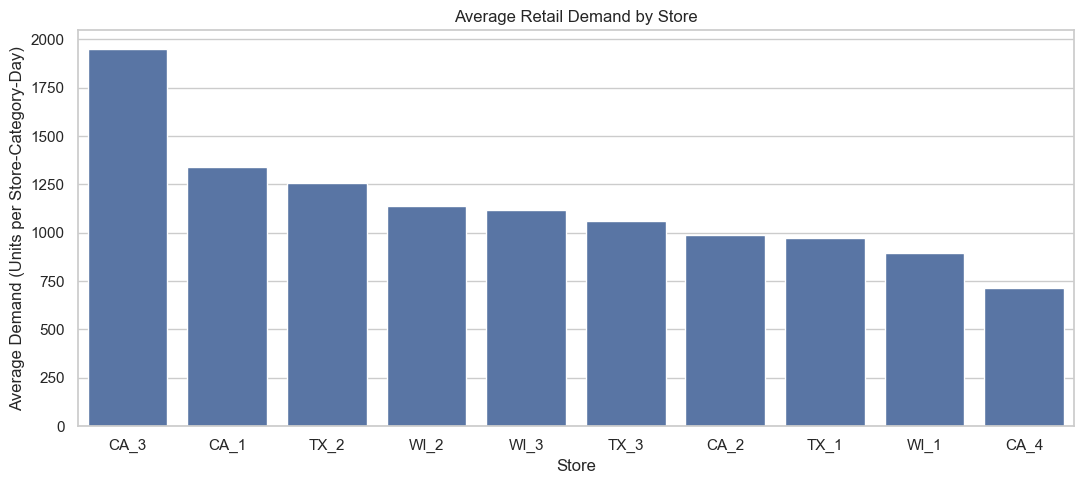

In [55]:
# 8.3 Plot average demand by store

plt.figure(figsize=(11, 5))

sns.barplot(
    data=store_demand,
    x="store_id",
    y="mean"
)

plt.title("Average Retail Demand by Store")
plt.xlabel("Store")
plt.ylabel("Average Demand (Units per Store-Category-Day)")

plt.tight_layout()
plt.show()

### 8.3 — Average Retail Demand by Store

This visualization compares average daily demand per store-category across Walmart's 10 stores.

**CA_3** records the highest average demand (**1,949.50 units**), followed by **CA_1 (1,341.39)** and **TX_2 (1,257.08)**. **CA_4** has the lowest average (**715.05 units**).

CA_3's demand is approximately **2.73 times** that of CA_4, highlighting substantial variation between stores within the same state.

**Forecasting implication:** These differences suggest that `store_id` may help models capture store-specific demand patterns beyond state-level averages.

## 8.4 Relative Demand by Store

To provide a relative comparison between stores, the average demand for each store is compared with the overall average demand across all store-category-day observations.

This percentage indicates how far each store's average demand is above or below the overall dataset average.

A positive percentage indicates that the store has above-average demand, while a negative percentage indicates below-average demand.

In [56]:
# 8.4 Calculate each store's difference from the overall average demand

store_demand["difference_from_overall_pct"] = (
    (store_demand["mean"] - overall_avg_demand)
    / overall_avg_demand
) * 100

store_demand

,store_id,mean,sum,median,demand_share_pct,difference_from_overall_pct
2,CA_3,1949.499913,11188180,1433.0,17.030383,70.303834
0,CA_1,1341.386304,7698216,737.0,11.718043,17.180426
5,TX_2,1257.080328,7214384,796.0,10.981565,9.815649
8,WI_2,1140.270430,6544012,735.0,9.961141,-0.388595
9,WI_3,1120.017773,6427782,619.0,9.784218,-2.157820
6,TX_3,1061.043736,6089330,730.0,9.269034,-7.309657
1,CA_2,990.673462,5685475,757.0,8.654296,-13.457042
4,TX_1,974.959401,5595292,714.0,8.517021,-14.829787
7,WI_1,897.205436,5149062,545.0,7.837781,-21.622194
3,CA_4,715.050706,4103676,409.0,6.246519,-37.534813


### 8.4 — Relative Demand by Store

This analysis measures how each store's average demand differs from the overall dataset average of **1,144.72 units per store-category-day**.

**CA_3 (+70.30%)**, **CA_1 (+17.18%)**, and **TX_2 (+9.82%)** are the only stores above the overall average.

In contrast, **CA_4 (−37.53%)** and **WI_1 (−21.62%)** show the largest negative deviations.

These differences highlight substantial variation in demand intensity across individual stores, including those within the same state.

**Forecasting implication:** Store-specific information may be important for capturing differences in baseline demand and improving forecasts across store-category combinations.

## 8.5 Relative Retail Demand by Store

The following visualization shows each store's average demand relative to the overall dataset average.

The zero line represents the overall average demand. Stores above zero have higher-than-average demand, while stores below zero have lower-than-average demand.

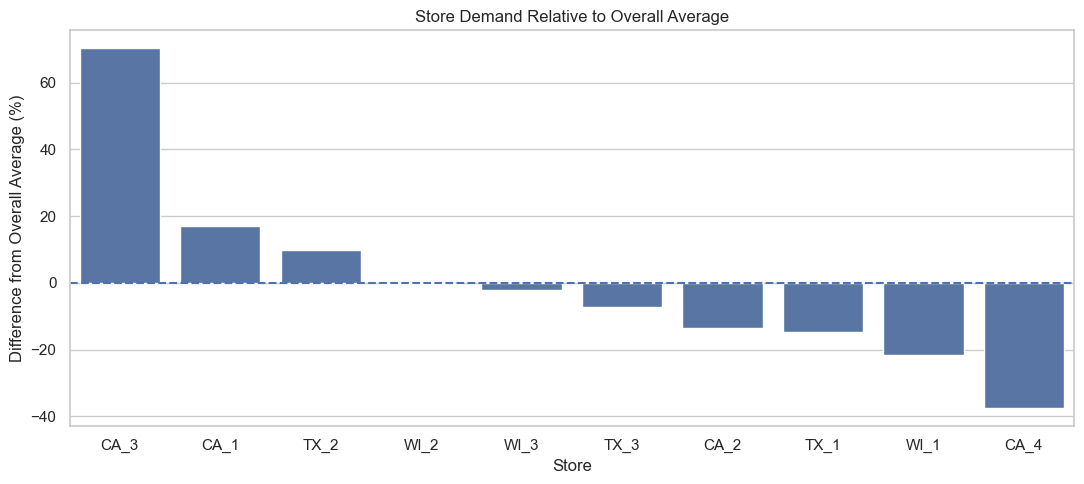

In [57]:
# 8.5 Plot store demand relative to the overall average

plt.figure(figsize=(11, 5))

sns.barplot(
    data=store_demand,
    x="store_id",
    y="difference_from_overall_pct"
)

plt.axhline(0, linestyle="--")

plt.title("Store Demand Relative to Overall Average")
plt.xlabel("Store")
plt.ylabel("Difference from Overall Average (%)")

plt.tight_layout()
plt.show()

The relative-demand graph shows substantial variation in demand intensity across individual stores. CA_3 has the highest average demand at 1,949.50 units per store-category-day, which is 70.30% above the overall average of 1,144.72. In contrast, CA_4 records the lowest average demand at 715.05 units, which is 37.53% below the overall average. Only three stores—CA_3, CA_1, and TX_2—are clearly above the overall average, while WI_2 is almost exactly at the average. The large variation between stores, including differences within the same state, indicates that store-level information may be important for accurately forecasting future demand.

## 8.6 — Store-Level Demand: Key Findings

The analysis reveals substantial differences in retail demand across Walmart's 10 stores.

**CA_3** records the highest average demand (**1,949.50 units per store-category-day**), approximately **70.30% above** the overall average of 1,144.72 units. CA_1 (+17.18%) and TX_2 (+9.82%) also exceed the overall average.

In contrast, **CA_4** has the lowest average demand (**715.05 units; −37.53%**), followed by WI_1 (897.21 units; −21.62%).

CA_3 contributes the largest share of total demand (**17.03%**), while CA_4 contributes the smallest (**6.25%**).

Importantly, CA_3's average demand is **2.73 times** that of CA_4, demonstrating substantial variation even within California. This suggests that state-level averages alone cannot fully represent individual store demand patterns.

**Forecasting implication:** The observed heterogeneity supports including `store_id` alongside `state_id` to capture location-specific demand differences. However, the analysis is descriptive and does not establish the causes of these variations.

**Conclusion:** Store identity is a potentially valuable feature for developing accurate store-category-level demand forecasts.

# Step 9 — Demand by Product Category

### Research Question

**How does retail demand differ across Walmart's product categories, and what implications do these differences have for demand forecasting?**

### Objective

This analysis examines demand across the three product categories in the M5 dataset: **FOODS, HOUSEHOLD, and HOBBIES**.

We compare average demand, total sales volume, and category-level demand patterns to identify differences in demand intensity and contribution to overall retail sales.

### Forecasting Relevance

Understanding category-level differences helps determine whether `category` should be retained as a predictive feature, allowing forecasting models to capture product-specific demand patterns across stores.

## 9.1 Category-Level Demand

The first step is to calculate demand statistics for each product category.

We calculate the mean, total, and median demand for each category. The mean allows us to compare the typical demand level across categories, while total demand shows each category's overall contribution to observed demand. The median provides an additional measure of typical demand that is less influenced by unusually high observations.

In [58]:
# 9.1 Calculate demand statistics for each product category

category_demand = (
    df.groupby("category")["demand"]
      .agg(["mean", "sum", "median"])
      .reset_index()
      .sort_values("mean", ascending=False)
)

category_demand

,category,mean,sum,median
0,FOODS,2357.027653,45089939,2204.0
2,HOUSEHOLD,756.961317,14480670,697.0
1,HOBBIES,320.167277,6124800,296.0


### 9.1 — Category-Level Demand Statistics

This analysis compares mean, total, and median retail demand across **FOODS, HOUSEHOLD, and HOBBIES**.

**FOODS** records the highest average demand (**2,357.03 units per store-category-day**), followed by **HOUSEHOLD (756.96)** and **HOBBIES (320.17)**.

FOODS demand is approximately **7.36 times higher than HOBBIES**, demonstrating substantial differences in demand levels across product categories.

FOODS also contributes the largest total demand (**45.09 million units**), while HOBBIES contributes the smallest (**6.12 million units**).

**Forecasting implication:** These differences support retaining `category` as a predictive feature to capture category-specific demand levels.

## 9.2 Category Demand Share

To complement the average-demand analysis, we calculate the percentage contribution of each product category to total observed demand.

This shows how much of the total demand in the dataset is associated with FOODS, HOUSEHOLD, and HOBBIES.

The demand share is calculated using total demand rather than average demand because the objective is to measure each category's contribution to the overall demand volume.

In [59]:
# 9.2 Calculate each category's share of total demand

category_demand["demand_share_pct"] = (
    category_demand["sum"] / category_demand["sum"].sum()
) * 100

category_demand

,category,mean,sum,median,demand_share_pct
0,FOODS,2357.027653,45089939,2204.0,68.634840
2,HOUSEHOLD,756.961317,14480670,697.0,22.042134
1,HOBBIES,320.167277,6124800,296.0,9.323026


### 9.2 — Percentage Share of Total Demand by Category

This analysis examines how each product category contributes to Walmart's total observed retail demand.

**FOODS dominates with 68.63%** of total demand, followed by **HOUSEHOLD (22.04%)** and **HOBBIES (9.32%)**.

Together, FOODS and HOUSEHOLD account for **90.68%** of total demand, indicating that most observed sales volume is concentrated in these two categories.

**Forecasting implication:** Category-level differences support including `category` as a predictive feature. Evaluating forecast errors separately by category will also help determine whether the model performs consistently across high- and low-demand categories.

## 9.3 Average Retail Demand by Product Category

The following visualization compares the average demand across the three product categories.

Average demand is used to compare the typical demand level of each category and provides a direct comparison of demand intensity between FOODS, HOUSEHOLD, and HOBBIES.

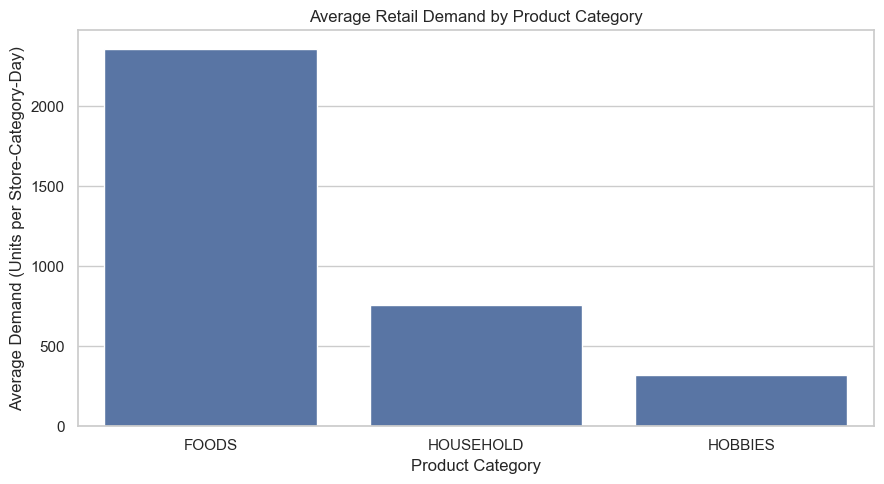

In [60]:
# 9.3 Plot average demand by product category

plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_demand,
    x="category",
    y="mean"
)

plt.title("Average Retail Demand by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Demand (Units per Store-Category-Day)")

plt.tight_layout()
plt.show()

### Average Demand by Product Category — Key Findings

The visualization shows substantial differences in average retail demand across the three product categories.

FOODS has the highest average demand at approximately **2,357.03 units per store-category-day**. This is approximately **3.11 times** the average demand of HOUSEHOLD, which records **756.96 units**. FOODS demand is also approximately **7.36 times** the average demand of HOBBIES, which records **320.17 units**.

HOUSEHOLD has an intermediate demand level, while HOBBIES records the lowest average demand.

**Forecasting implication:** The magnitude of these differences indicates that product category is an important source of demand variation in the dataset. Consequently, category information should be retained as a potential predictive feature in the forecasting model.

These results are descriptive and do not establish the reasons for the differences between categories. They demonstrate that the typical demand level varies substantially depending on the product category.

## 9.4 Relative Demand by Product Category

To provide a relative comparison, the average demand for each product category is compared with the overall dataset average of 1,144.72 units per store-category-day.

The resulting percentage shows how far each category's average demand is above or below the overall average.

A positive percentage indicates above-average demand, while a negative percentage indicates below-average demand.

In [61]:
# Calculate each category's difference from the overall average demand

category_demand["difference_from_overall_pct"] = (
    (category_demand["mean"] - overall_avg_demand)
    / overall_avg_demand
) * 100

category_demand

,category,mean,sum,median,demand_share_pct,difference_from_overall_pct
0,FOODS,2357.027653,45089939,2204.0,68.634840,105.904521
2,HOUSEHOLD,756.961317,14480670,697.0,22.042134,-33.873598
1,HOBBIES,320.167277,6124800,296.0,9.323026,-72.030922


### 9.4 — Relative Demand by Product Category

This analysis compares each product category's average demand against the overall dataset average of **1,144.72 units per store-category-day**.

**FOODS (+105.90%)** records average demand more than twice the overall average, while **HOUSEHOLD (−33.87%)** and **HOBBIES (−72.03%)** fall substantially below it.

These differences demonstrate considerable variation in demand intensity across product categories, with FOODS dominating overall demand.

**Forecasting implication:** Including `category` may help forecasting models capture category-specific demand levels. Category-level evaluation will also be important for assessing prediction accuracy across different demand scales.

### Relative Demand by Product Category — Key Findings

The relative-demand analysis further highlights the substantial differences in demand across product categories.

FOODS has an average demand of approximately **2,357.03 units per store-category-day**, which is **105.90% above the overall dataset average** of 1,144.72 units. This indicates that the typical demand level for FOODS is more than twice the overall average.

HOUSEHOLD records an average demand of approximately **756.96 units**, which is **33.87% below the overall average**. HOBBIES has the lowest average demand at approximately **320.17 units**, or **72.03% below the overall average**.

These differences demonstrate that product category is strongly associated with the level of retail demand in the dataset. Therefore, category information should be retained as an important predictive feature in the forecasting model.

The percentages describe differences in observed demand levels and do not establish the underlying causes of these differences. Factors such as product type, purchasing behavior, and product assortment may contribute, but these factors are not separately tested in this analysis.

## 9.4 Relative Demand by Product Category — Visualization

The following visualization compares each product category's average demand with the overall dataset average.

The horizontal reference line at 0% represents the overall average demand. Categories above the line have higher-than-average demand, while categories below the line have lower-than-average demand.

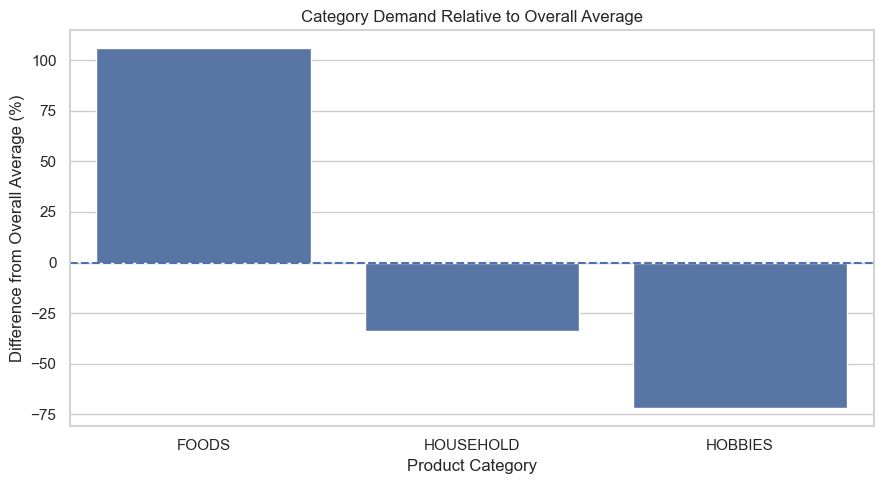

In [62]:
# 9.4 Plot each category's demand relative to the overall dataset average

plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_demand,
    x="category",
    y="difference_from_overall_pct"
)

# Reference line representing the overall average
plt.axhline(0, linestyle="--")

plt.title("Category Demand Relative to Overall Average")
plt.xlabel("Product Category")
plt.ylabel("Difference from Overall Average (%)")

plt.tight_layout()
plt.show()

## 9.5 — Product Category Demand: Final Findings

**Research Question:** How does retail demand differ across Walmart's product categories, and what implications do these differences have for demand forecasting?

### Key Findings

Retail demand differs substantially across the three product categories:

- **FOODS:** Highest average demand (**2,357.03 units per store-category-day**), contributing **68.63%** of total demand and exceeding the overall average by **105.90%**.
- **HOUSEHOLD:** Average demand of **756.96 units**, contributing **22.04%** of total demand and falling **33.87% below** the overall average.
- **HOBBIES:** Lowest average demand (**320.17 units**), contributing **9.32%** of total demand and falling **72.03% below** the overall average.

FOODS records approximately **7.36 times** the average demand of HOBBIES, demonstrating substantial differences in demand intensity across categories.

### Forecasting Implications

These differences support retaining `category` as a predictive feature to capture category-specific demand levels. Forecast accuracy should also be evaluated separately for each category to account for their different demand scales.

The findings are descriptive and do not establish the underlying causes of these differences.

### Conclusion — Answer to the Research Question

**Yes, retail demand differs substantially across product categories.** FOODS dominates both average and total demand, while HOBBIES has the lowest demand.

Therefore, **product category is an important candidate predictor** for the machine-learning forecasting model, although its contribution to predictive accuracy must be confirmed during model evaluation.

# Step 10 — Holidays and Special Events

### Research Question

**How does Walmart's retail demand vary during holidays and special events, and can event-related information help improve demand forecasting?**

### Objective

This analysis investigates whether retail demand differs between regular days and days associated with holidays or special events recorded in the M5 calendar.

Events include **Christmas, Thanksgiving, Easter, the Super Bowl**, and other cultural, religious, and sporting occasions.

The analysis will examine demand patterns across event and non-event days, including differences by event type where appropriate.

### Forecasting Relevance

Identifying event-related demand patterns can help assess the usefulness of calendar features such as `event_name_1`, `event_type_1`, `event_name_2`, and `event_type_2` in forecasting models.

**Important consideration:** Observed demand differences are descriptive and do not establish that holidays or events directly cause changes in retail demand.

## 10.1 Demand on Event Days vs Non-Event Days

The M5 calendar contains information about special events and holidays through the `event_name_1` and `event_name_2` variables.

To examine whether demand differs on event days, an event indicator will be created. A day will be classified as an **event day** if at least one event is recorded in either event field.

Average demand will then be compared between event days and non-event days.

This analysis is descriptive: differences in demand between the two groups indicate an association in the observed data but do not establish that the events themselves caused the differences.

In [63]:
# 10.1 Create an indicator for whether a day has at least one recorded event

df["is_event_day"] = (
    df["event_name_1"].notna() |
    df["event_name_2"].notna()
).astype(int)

# Compare demand between event and non-event days

event_demand = (
    df.groupby("is_event_day")["demand"]
      .agg(["mean", "sum", "median", "count"])
      .reset_index()
)

# Replace the numeric indicator with readable labels

event_demand["day_type"] = event_demand["is_event_day"].map({
    0: "Non-event day",
    1: "Event day"
})

event_demand

,is_event_day,mean,sum,median,count,day_type
0,0,1149.640250,60666516,707.0,52770,Non-event day
1,1,1088.504978,5028893,642.5,4620,Event day


### 10.1 — Retail Demand on Event vs. Non-Event Days

This analysis compares average retail demand between days with recorded calendar events and regular days.

**Non-event days** record higher average demand (**1,149.64 units per store-category-day**) than **event days (1,088.50 units)**, representing a **5.32% decrease** on event days.

Median demand follows a similar pattern, declining from **707 units** on non-event days to **642.5 units** on event days.

These findings suggest that event-related calendar information may help explain demand variation. However, different events may have different demand patterns, and the observed association does not establish causation.

**Forecasting implication:** Event indicators are useful candidate features, but individual event types should be examined before drawing broader conclusions.

## 10.2 Event-Day vs Non-Event-Day Demand — Visualization

The following visualization compares average retail demand between days with at least one recorded event and days without a recorded event.

The comparison provides a visual representation of the difference identified in the previous analysis.

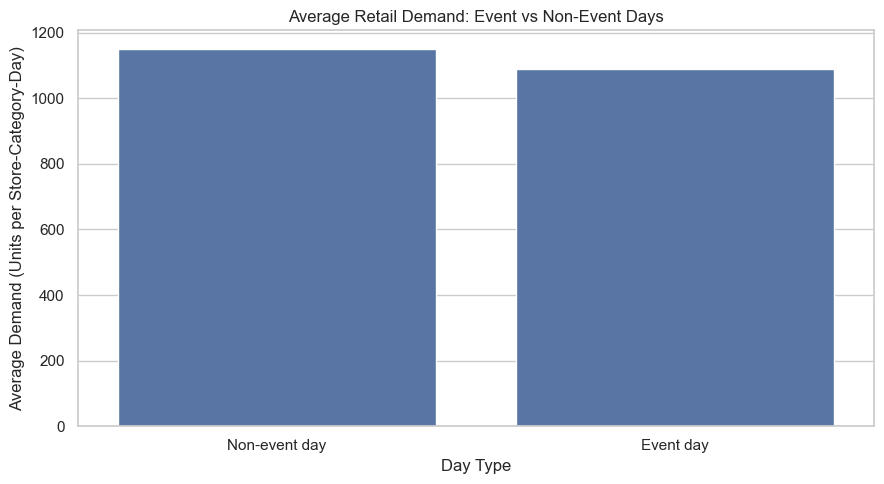

In [64]:
# 10.2 Visualize average demand on event and non-event days

plt.figure(figsize=(9, 5))

sns.barplot(
    data=event_demand,
    x="day_type",
    y="mean"
)

plt.title("Average Retail Demand: Event vs Non-Event Days")
plt.xlabel("Day Type")
plt.ylabel("Average Demand (Units per Store-Category-Day)")

plt.tight_layout()
plt.show()

### 10.2 — Average Retail Demand: Event vs. Non-Event Days

This visualization compares average demand on days with recorded special events against regular days.

**Non-event days (1,149.64 units)** show higher average demand than **event days (1,088.50 units)**, representing a **5.32% lower average** on event days.

However, this overall difference may conceal variations between individual holidays and event types.

**Forecasting implication:** Event-related features may help capture calendar-associated demand patterns, but further analysis is needed to determine which events are most informative.

### 10.3 Event-Day Demand Difference

To quantify the difference observed in the previous comparison, the average demand on event days will be compared directly with the average demand on non-event days.

The percentage difference is calculated relative to non-event-day demand. This provides a clearer measure of how much higher or lower demand is on event days.

In [65]:
# 10.3 Extract average demand for each day type

non_event_avg = event_demand.loc[
    event_demand["is_event_day"] == 0, "mean"
].iloc[0]

event_avg = event_demand.loc[
    event_demand["is_event_day"] == 1, "mean"
].iloc[0]

# Calculate the percentage difference relative to non-event days

event_difference_pct = (
    (event_avg - non_event_avg)
    / non_event_avg
) * 100

print(f"Non-event day average demand: {non_event_avg:,.2f}")
print(f"Event day average demand: {event_avg:,.2f}")
print(f"Event-day demand difference: {event_difference_pct:.2f}%")

Non-event day average demand: 1,149.64
Event day average demand: 1,088.50
Event-day demand difference: -5.32%


### 10.3 — Percentage Difference in Event-Day Demand

This analysis measures the percentage difference in average retail demand between event and non-event days.

Average demand is **1,149.64 units on non-event days** compared with **1,088.50 units on event days**, representing a **−5.32% difference**.

The negative percentage indicates that average demand is **5.32% lower on event days**, not higher.

**Forecasting implication:** Event-related features may help capture demand variations, although the observed difference does not establish causation and may vary across individual events.

## 10.4 Demand by Event Type

The previous analysis treated all recorded events as one group. However, different types of events may be associated with different demand patterns.

To investigate this variation, the available event-type information will be examined. The analysis will focus on the event types recorded in the M5 calendar and compare their average retail demand.

Because some days may contain two event records, the analysis will first combine the available event-type information into a single field for descriptive analysis.

In [66]:
# 10.4 Create a combined event-type field

df["event_type_combined"] = (
    df["event_type_1"]
    .fillna(df["event_type_2"])
)

# Keep only observations with a recorded event type

event_type_demand = (
    df[df["event_type_combined"].notna()]
    .groupby("event_type_combined")["demand"]
    .agg(["mean", "sum", "median", "count"])
    .reset_index()
    .sort_values("mean", ascending=False)
)

event_type_demand

,event_type_combined,mean,sum,median,count
3,Sporting,1193.202083,572737,676.5,480
0,Cultural,1141.158095,1198216,684.0,1050
2,Religious,1125.356410,1755556,684.0,1560
1,National,981.950327,1502384,543.0,1530


In [67]:
# 10.4.1 Calculate each event type's difference from the overall average demand

event_type_demand["difference_from_overall_pct"] = (
    (event_type_demand["mean"] - overall_avg_demand)
    / overall_avg_demand
) * 100

event_type_demand

,event_type_combined,mean,sum,median,count,difference_from_overall_pct
3,Sporting,1193.202083,572737,676.5,480,4.235393
0,Cultural,1141.158095,1198216,684.0,1050,-0.311051
2,Religious,1125.356410,1755556,684.0,1560,-1.691449
1,National,981.950327,1502384,543.0,1530,-14.219075


### Event Type — Key Findings

The event-type analysis reveals substantial variation in observed retail demand across different types of recorded events.

**Sporting events** have the highest average demand at approximately **1,193.20 units per store-category-day**, which is **4.24% relative to the overall dataset average** of 1,144.72 units.

**Cultural events** have an average demand of approximately **1,141.16 units**, which is only **-0.31% below the overall average**. 

**Religious events** record approximately **1,125.36 units**, or **-1.69% below the overall average**.

**National events** have the lowest average demand at approximately **981.95 units**, representing a difference of **−14.22% from the overall average**.

These findings demonstrate that treating all events as a single category can conceal important differences in demand patterns. In particular, the positive difference observed for Sporting events contrasts with the substantially lower demand observed for National events.

The results are descriptive and indicate associations between event type and observed demand. They do not establish that a particular event type causes demand to increase or decrease, since event dates may also coincide with specific weekdays, seasons, prices, SNAP availability, or other factors.

**Forecasting implication:** From a forecasting perspective, the findings support retaining event-related information as potential predictive features rather than relying only on a simple event-day indicator.

## 10.5 Event Type Relative to Overall Average — Visualization

The following visualization compares the average demand associated with each event type relative to the overall dataset average.

The horizontal reference line at 0% represents the overall average demand. Positive values indicate above-average demand, while negative values indicate below-average demand.

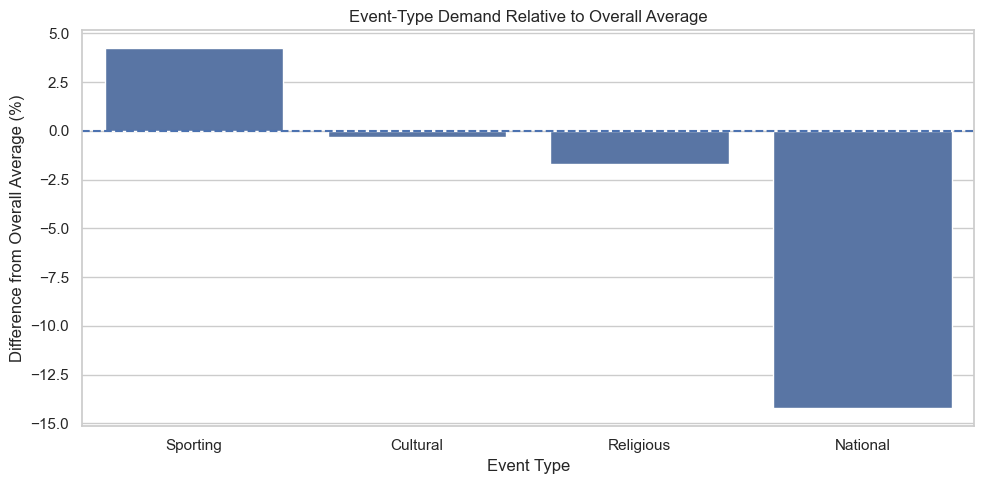

In [68]:
# 10.5 Visualize event-type demand relative to the overall average

plt.figure(figsize=(10, 5))

sns.barplot(
    data=event_type_demand,
    x="event_type_combined",
    y="difference_from_overall_pct"
)

# Reference line representing the overall average
plt.axhline(0, linestyle="--")

plt.title("Event-Type Demand Relative to Overall Average")
plt.xlabel("Event Type")
plt.ylabel("Difference from Overall Average (%)")

plt.tight_layout()
plt.show()

### 10.5 — Event-Type Demand Relative to Overall Average

This visualization compares average demand across event types against the overall dataset average of **1,144.72 units per store-category-day**.

**Sporting events (+4.24%)** are the only event type above the overall average.

In contrast, **Cultural (−0.31%)** and **Religious (−1.69%)** events show relatively small negative deviations, while **National events (−14.22%)** record the largest decrease relative to the overall average.

These differences suggest that event types are associated with distinct demand patterns rather than a uniform change across all events.

**Forecasting implication:** Event-type features may provide more useful information than a single event-day indicator, although their predictive value must be tested.

## 10.6 Demand by Individual Holiday and Event

Event types provide a broad classification, but individual events may have substantially different relationships with retail demand.

This analysis examines the specific event names recorded in the M5 calendar and compares their average observed demand.

Only observations with a recorded event name are included in this analysis. Days without an event are excluded so that the comparison focuses specifically on differences between individual events.

In [69]:
# 10.6 Combine the two possible event-name fields

df["event_name_combined"] = (
    df["event_name_1"]
    .fillna(df["event_name_2"])
)

# Calculate demand statistics for each individual event

event_name_demand = (
    df[df["event_name_combined"].notna()]
    .groupby("event_name_combined")["demand"]
    .agg(["mean", "sum", "median", "count"])
    .reset_index()
    .sort_values("mean", ascending=False)
)

event_name_demand

,event_name_combined,mean,sum,median,count
10,LaborDay,1405.153333,210773,849.0,150
26,SuperBowl,1364.133333,245544,780.0,180
4,Easter,1317.253333,197588,755.0,150
20,OrthodoxEaster,1275.900000,153108,747.0,120
7,Father's day,1218.733333,146248,740.5,120
23,Purim End,1198.566667,215742,751.0,180
5,Eid al-Fitr,1175.586667,176338,718.5,150
3,ColumbusDay,1172.160000,175824,666.0,150
29,VeteransDay,1170.626667,175594,699.0,150
24,Ramadan starts,1159.320000,173898,702.5,150


In [70]:
# 10.6.1 Calculate each individual event's difference from the overall average

event_name_demand["difference_from_overall_pct"] = (
    (event_name_demand["mean"] - overall_avg_demand)
    / overall_avg_demand
) * 100

event_name_demand

,event_name_combined,mean,sum,median,count,difference_from_overall_pct
10,LaborDay,1405.153333,210773,849.0,150,22.750967
26,SuperBowl,1364.133333,245544,780.0,180,19.167554
4,Easter,1317.253333,197588,755.0,150,15.072225
20,OrthodoxEaster,1275.900000,153108,747.0,120,11.459693
7,Father's day,1218.733333,146248,740.5,120,6.465744
23,Purim End,1198.566667,215742,751.0,180,4.704030
5,Eid al-Fitr,1175.586667,176338,718.5,150,2.696550
3,ColumbusDay,1172.160000,175824,666.0,150,2.397205
29,VeteransDay,1170.626667,175594,699.0,150,2.263256
24,Ramadan starts,1159.320000,173898,702.5,150,1.275532


### Individual Holidays and Events — Key Findings

The individual-event analysis reveals substantial variation in observed retail demand across specific holidays and special events.

LaborDay records the highest average demand among the identified events at approximately **1,405.15 units per store-category-day**, followed by SuperBowl at **1,364.13 units** and Easter at **1,317.25 units**.

Several events are associated with demand levels above the overall dataset average of 1,144.72 units. For example, LaborDay is approximately **22.75% above the overall average**, while SuperBowl is approximately **19.17% above the overall average** and Easter is approximately **15.07% above the overall average**

At the lower end, Thanksgiving records an *average demand of approximately* **704.33 units,**, which is around **38.47% below the overall average**. NewYear records approximately **858.95 units**, or about **24.97% below the overall average**.

**Christmas** is a particularly unusual observation, with an average demand of only **0.52 units per store-category-day**, substantially below the other events. Because this value is an extreme outlier, it should be investigated further before drawing conclusions about Christmas-related demand.

**Forecasting implication:** Overall, the results demonstrate that individual events can be associated with very different observed demand levels. This suggests that event-related information may provide useful predictive information for the forecasting model.

However, these results are descriptive and do not establish that individual holidays or events caused demand to increase or decrease. Event dates may coincide with particular weekdays, seasons, prices, SNAP availability, or other factors that also influence demand.

## 10.6.2 Highest and Lowest Demand Events

Because the dataset contains a relatively large number of individual events, displaying all events in a single chart would make the visualization difficult to interpret.

Instead, the analysis will compare the five events with the highest average demand and the five events with the lowest average demand.

The comparison is descriptive and is intended to highlight the range of observed demand across individual events.

In [71]:
# 10.6.2 Select the five events with the highest average demand

top_events = (
    event_name_demand
    .sort_values("mean", ascending=False)
    .head(5)
)

# Select the five events with the lowest average demand

bottom_events = (
    event_name_demand
    .sort_values("mean", ascending=True)
    .head(5)
)

# Combine the two groups for visualization

selected_events = pd.concat(
    [top_events, bottom_events]
)

selected_events

,event_name_combined,mean,sum,median,count,difference_from_overall_pct
10,LaborDay,1405.153333,210773,849.0,150,22.750967
26,SuperBowl,1364.133333,245544,780.0,180,19.167554
4,Easter,1317.253333,197588,755.0,150,15.072225
20,OrthodoxEaster,1275.900000,153108,747.0,120,11.459693
7,Father's day,1218.733333,146248,740.5,120,6.465744
1,Christmas,0.520000,78,0.0,150,-99.954574
27,Thanksgiving,704.333333,105650,362.5,150,-38.471058
18,NewYear,858.946667,128842,557.0,150,-24.964393
12,LentWeek2,991.566667,178482,653.5,180,-13.379014
8,Halloween,1001.980000,150297,618.0,150,-12.469329


### 10.6.2 — Highest and Lowest Demand Events

This analysis identifies the five events associated with the highest and lowest average retail demand.

**Labor Day (+22.75%)**, **Super Bowl (+19.17%)**, and **Easter (+15.07%)** show the largest positive deviations from the overall average.

Conversely, **Christmas (−99.95%)**, **Thanksgiving (−38.47%)**, and **New Year (−24.96%)** show the largest negative deviations, with Christmas recording almost zero demand.

These contrasting patterns highlight substantial differences between individual holidays and special events.

**Forecasting implication:** Event-specific calendar features may help forecasting models account for unusually high or low demand periods, particularly major holidays.

## 10.6.3 Highest and Lowest Demand Events

The following visualization compares the five individual events with the highest average demand and the five with the lowest average demand.

This provides a clearer view of the range of observed demand across individual events without overcrowding the visualization with every event in the dataset.

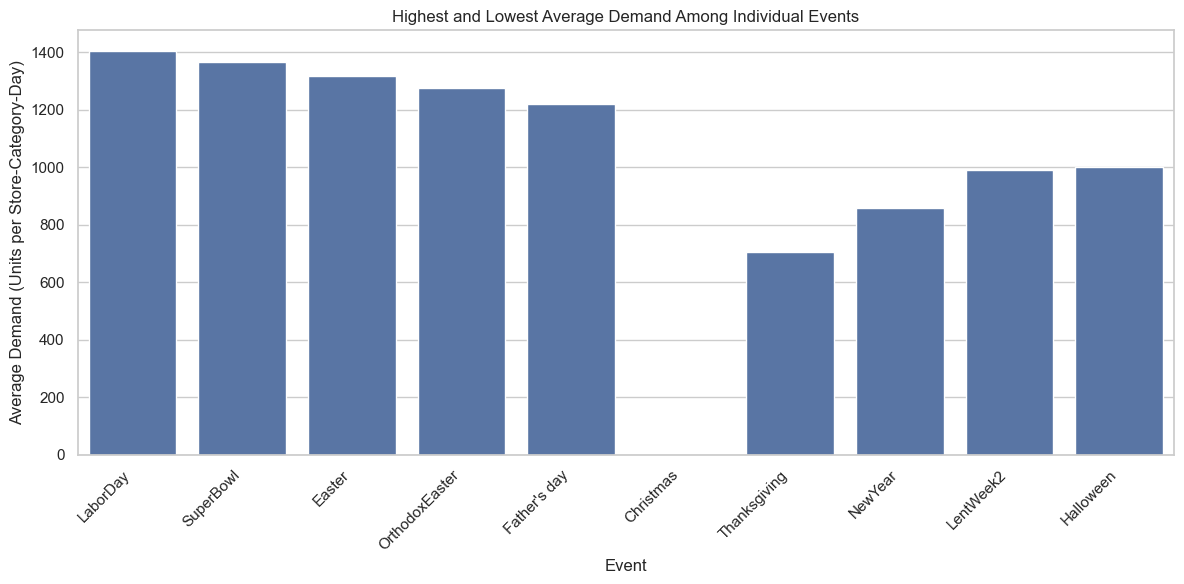

In [73]:
# 10.6.3 Select the five events with the highest average demand

top_events = (
    event_name_demand
    .sort_values("mean", ascending=False)
    .head(5)
)

# Select the five events with the lowest average demand

bottom_events = (
    event_name_demand
    .sort_values("mean", ascending=True)
    .head(5)
)

# Combine the two groups

selected_events = pd.concat(
    [top_events, bottom_events]
)

# Plot the selected events

plt.figure(figsize=(12, 6))

sns.barplot(
    data=selected_events,
    x="event_name_combined",
    y="mean"
)

plt.title("Highest and Lowest Average Demand Among Individual Events")
plt.xlabel("Event")
plt.ylabel("Average Demand (Units per Store-Category-Day)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### 10.6.3 — Highest and Lowest Average Demand Events

This visualization highlights the five highest- and five lowest-demand events recorded in the M5 dataset.

**Labor Day (1,405.15 units)**, **Super Bowl (1,364.13 units)**, and **Easter (1,317.25 units)** have the highest average demand.

Conversely, **Christmas (0.52 units)**, **Thanksgiving (704.33 units)**, and **New Year (858.95 units)** have the lowest averages.

The substantial differences demonstrate that retail demand varies considerably across individual events, although the analysis does not establish causation.

**Forecasting implication:** Event-specific calendar features may help models anticipate unusual demand patterns, particularly the near-zero demand observed on Christmas.

### 10.7 Investigating the Christmas Demand Observation

Christmas has an unusually low average demand compared with all other recorded events. Before interpreting this observation, it is important to examine the underlying dates and demand values.

This validation step checks whether the extremely low average is consistently observed across Christmas dates and store-category combinations, rather than being caused by an isolated data-quality issue or an aggregation artifact.

In [74]:
# 10.7 Inspect all Christmas observations
christmas_data = df[
    df["event_name_combined"].eq("Christmas")
][
    [
        "date",
        "day_id",
        "weekday",
        "weekday_num",
        "demand",
        "store_id",
        "category",
        "event_name_combined"
    ]
].sort_values("date")

christmas_data.head(20)

,date,day_id,weekday,weekday_num,demand,store_id,category,event_name_combined
330,2011-12-25,d_331,Sunday,2,0,CA_1,FOODS,Christmas
34764,2011-12-25,d_331,Sunday,2,2,TX_3,FOODS,Christmas
17547,2011-12-25,d_331,Sunday,2,0,CA_4,FOODS,Christmas
9895,2011-12-25,d_331,Sunday,2,0,CA_2,HOUSEHOLD,Christmas
32851,2011-12-25,d_331,Sunday,2,0,TX_2,HOUSEHOLD,Christmas
30938,2011-12-25,d_331,Sunday,2,0,TX_2,HOBBIES,Christmas
11808,2011-12-25,d_331,Sunday,2,1,CA_3,FOODS,Christmas
29025,2011-12-25,d_331,Sunday,2,0,TX_2,FOODS,Christmas
27112,2011-12-25,d_331,Sunday,2,0,TX_1,HOUSEHOLD,Christmas
13721,2011-12-25,d_331,Sunday,2,0,CA_3,HOBBIES,Christmas


In [75]:
# 10.7.1 Summarize demand across each Christmas date
christmas_summary = (
    df[df["event_name_combined"].eq("Christmas")]
    .groupby("date")["demand"]
    .agg(
        total_demand="sum",
        average_demand="mean",
        minimum_demand="min",
        maximum_demand="max",
        observations="count"
    )
    .reset_index()
)

christmas_summary

,date,total_demand,average_demand,minimum_demand,maximum_demand,observations
0,2011-12-25,13,0.433333,0,7,30
1,2012-12-25,11,0.366667,0,4,30
2,2013-12-25,20,0.666667,0,11,30
3,2014-12-25,20,0.666667,0,7,30
4,2015-12-25,14,0.466667,0,4,30


In [76]:
# 10.7.2 Display all Christmas dates in the dataset
christmas_dates = (
    df.loc[
        df["event_name_combined"].eq("Christmas"),
        "date"
    ]
    .drop_duplicates()
    .sort_values()
)

christmas_dates

330    2011-12-25
696    2012-12-25
1061   2013-12-25
1426   2014-12-25
1791   2015-12-25
Name: date, dtype: datetime64[ns]

### Christmas Demand Validation — Key Finding

The extremely low demand observed for Christmas was investigated to determine whether it represented an isolated data-quality issue or a consistent pattern in the dataset.

The validation shows that the pattern is consistent across all five Christmas dates available in the M5 historical period. Total demand across the 30 store-category observations ranges from only **11 to 20 units per Christmas date**, with average demand ranging from approximately **0.37 to 0.67 units per store-category-day**.

The five Christmas dates therefore consistently exhibit extremely low demand compared with the overall dataset average of **1,144.72 units per store-category-day**. The result is not driven by a single unusual year.

This finding indicates that Christmas is an important calendar-related pattern in the M5 data. It also demonstrates why a simple binary event indicator may not be sufficient to capture all event-related demand variation. Individual event information can provide additional predictive information for the forecasting model.

However, the analysis remains descriptive. The results show a strong association between Christmas dates and very low observed demand, but they do not establish a causal effect.

**Forecasting implication:** For the forecasting stage, the Christmas pattern should therefore be retained through the event/calendar features rather than treated as a data-quality error.

## 10.8 — Holidays and Special Events: Final Findings

**Research Question:** How does Walmart's retail demand vary during holidays and special events, and can event-related information help improve demand forecasting?

### Key Findings

Retail demand varies considerably across holidays and special events.

- **Event vs. non-event days:** Average demand is **−5.32% lower** on event days (1,088.50 units) compared with non-event days (1,149.64 units).
- **Event types:** Sporting events record demand **+4.24% above** the overall dataset average, while National events record **−14.22% below** it.
- **Individual events:** Labor Day (+22.75%), Super Bowl (+19.17%), and Easter (+15.07%) show the highest positive deviations. Thanksgiving (−38.47%) and New Year (−24.96%) show substantial negative deviations.
- **Christmas:** Demand is exceptionally low (**−99.95% relative to the overall average**), with near-zero sales consistently observed across all five Christmas dates (2011–2015).

These results demonstrate that individual events are associated with different demand patterns, which a single event-day indicator cannot fully represent.

### Forecasting Implications

The findings support including event names, event types, and holiday indicators as candidate forecasting features, particularly to capture recurring patterns such as near-zero Christmas demand.

However, these are descriptive associations, not evidence of causation. The actual improvement in forecasting accuracy must be established through model evaluation.

### Conclusion — Answer to the Research Question

**Walmart's retail demand differs substantially across holidays and special events.** Some events are associated with above-average demand, while others, particularly Christmas, show unusually low demand.

Therefore, **event-related calendar information is a promising predictor of retail demand**, but whether it improves forecasting accuracy must be confirmed during machine-learning model validation.

## Step 11 — SNAP Availability and Retail Demand

### Research Question

**How does Walmart's retail demand differ between SNAP and non-SNAP days, and can SNAP availability provide useful information for demand forecasting?**

### Objective

This analysis investigates whether retail demand varies according to SNAP (Supplemental Nutrition Assistance Program) availability across California, Texas, and Wisconsin.

The cleaned dataset contains a state-specific `snap` indicator:

- **0:** SNAP not active
- **1:** SNAP active

We compare average demand, median demand, and percentage differences between SNAP and non-SNAP days to identify potential demand patterns.

### Forecasting Relevance

Understanding SNAP-related demand differences can help assess whether `snap` should be retained as a predictive feature, particularly when modeling demand across different states and product categories.

**Important consideration:** The analysis identifies associations, not causal effects. Observed differences may also reflect seasonality, holidays, store characteristics, and product categories.

In [77]:
# 11.1 Compare demand between SNAP and non-SNAP days

snap_demand = (
    df.groupby("snap")["demand"]
      .agg(["mean", "sum", "median", "count"])
      .reset_index()
)

snap_demand["day_type"] = snap_demand["snap"].map({
    0: "Non-SNAP",
    1: "SNAP"
})

snap_demand

,snap,mean,sum,median,count,day_type
0,0,1098.780047,42292044,690.5,38490,Non-SNAP
1,1,1238.273280,23403365,722.0,18900,SNAP


### 11.1 — Retail Demand on SNAP vs. Non-SNAP Days

This analysis compares average and median retail demand based on SNAP availability.

**SNAP days** record higher average demand (**1,238.27 units per store-category-day**) than **non-SNAP days (1,098.78 units)**, representing a **+12.70% difference**.

Median demand is also higher on SNAP days (**722 units**) compared with non-SNAP days (**690.5 units**).

These findings indicate a positive association between SNAP availability and observed retail demand, although they do not establish causation.

**Forecasting implication:** The `snap` indicator is a promising candidate feature for capturing SNAP-associated demand variation across states and product categories.

### SNAP vs Non-SNAP — Relative Difference

To make the comparison easier to interpret, the analysis also calculates the percentage difference in average demand between SNAP and non-SNAP observations.

The percentage difference is calculated relative to the average demand observed on non-SNAP days:

\[
\text{Percentage Difference} =
\frac{\text{SNAP Demand} - \text{Non-SNAP Demand}}
{\text{Non-SNAP Demand}}
\times 100
\]

This allows the difference to be interpreted as the percentage by which average demand on SNAP days is higher or lower than demand on non-SNAP days.

In [78]:
# 11.2 Extract average demand for each group

non_snap_avg = snap_demand.loc[
    snap_demand["snap"] == 0, "mean"
].iloc[0]

snap_avg = snap_demand.loc[
    snap_demand["snap"] == 1, "mean"
].iloc[0]

# Calculate percentage difference

snap_difference_pct = (
    (snap_avg - non_snap_avg)
    / non_snap_avg
) * 100

print(f"Non-SNAP average demand: {non_snap_avg:,.2f}")
print(f"SNAP average demand: {snap_avg:,.2f}")
print(f"SNAP demand difference: {snap_difference_pct:+.2f}%")

Non-SNAP average demand: 1,098.78
SNAP average demand: 1,238.27
SNAP demand difference: +12.70%


### 11.2 — Percentage Difference in SNAP-Day Demand

This analysis measures the relative difference in average retail demand between SNAP and non-SNAP days.

Average demand increases from **1,098.78 units on non-SNAP days** to **1,238.27 units on SNAP days**, representing a **+12.70% difference**.

This indicates a positive association between SNAP availability and retail demand, although the analysis does not establish causation.

**Forecasting implication:** Including `snap` as a predictive feature may help capture demand differences associated with SNAP availability.

### SNAP vs Non-SNAP Demand — Visualization

The following visualization compares average retail demand between SNAP and non-SNAP observations.

The chart provides a direct visual comparison of the two demand levels, while the percentage calculation above provides the relative magnitude of the difference.

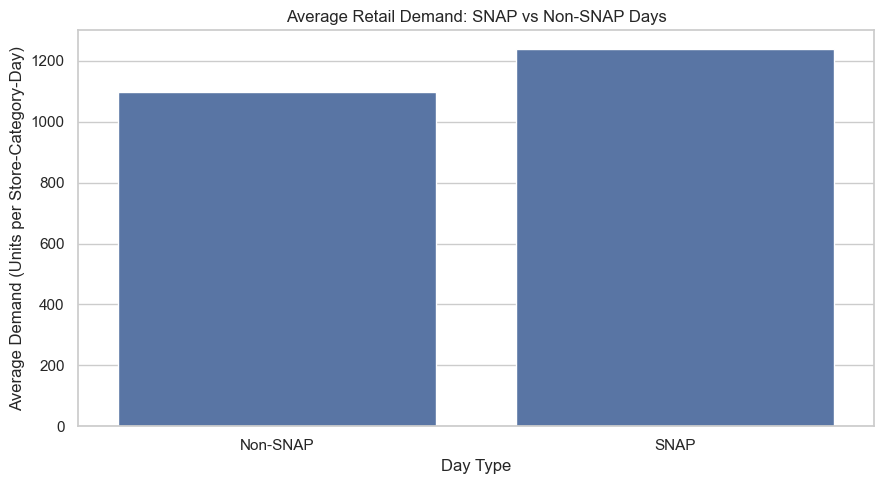

In [79]:
# 11.3 Visualize average demand on SNAP and non-SNAP days
plt.figure(figsize=(9, 5))

sns.barplot(
    data=snap_demand,
    x="day_type",
    y="mean"
)

plt.title("Average Retail Demand: SNAP vs Non-SNAP Days")
plt.xlabel("Day Type")
plt.ylabel("Average Demand (Units per Store-Category-Day)")

plt.tight_layout()
plt.show()

### SNAP vs Non-SNAP Demand — Key Finding

The comparison between SNAP and non-SNAP observations shows a noticeable difference in average retail demand.

Average demand on non-SNAP days is approximately **1,098.78 units per store-category-day**, while average demand on SNAP days is approximately **1,238.27 units**.

This represents a **12.70% higher average demand on SNAP days** relative to non-SNAP days. The median demand is also slightly higher on SNAP days, at **722 units compared with 690.5 units** on non-SNAP days.

The total demand for SNAP days is lower than the total demand for non-SNAP days because there are substantially fewer SNAP observations in the dataset. Therefore, average demand provides the more appropriate basis for comparison.

The observed difference suggests that SNAP availability may contain useful information for predicting retail demand. However, the result is descriptive and does not establish that SNAP availability itself causes higher demand. SNAP periods may overlap with other temporal patterns, such as particular days of the month, weekdays, seasonal periods, or holidays.

**Forecasting implication:** For the forecasting model, SNAP availability will therefore be retained as a potential predictive feature rather than interpreted as a causal factor.

## 11.4 SNAP Demand by State

Because SNAP availability varies by state, the overall SNAP comparison may conceal differences between geographic markets.

This analysis compares average demand during SNAP and non-SNAP periods separately for California (CA), Texas (TX), and Wisconsin (WI).

Examining the states separately provides a more detailed understanding of whether the observed relationship between SNAP availability and demand is consistent across the different markets represented in the M5 dataset.

In [80]:
# 11.4 Compare average demand by state and SNAP status

snap_state_demand = (
    df.groupby(["state_id", "snap"])["demand"]
      .agg(["mean", "sum", "median", "count"])
      .reset_index()
)

snap_state_demand["day_type"] = snap_state_demand["snap"].map({
    0: "Non-SNAP",
    1: "SNAP"
})

snap_state_demand

,state_id,snap,mean,sum,median,count,day_type
0,CA,0,1217.151143,18739259,735.0,15396,Non-SNAP
1,CA,1,1314.323810,9936288,765.5,7560,SNAP
2,TX,0,1057.675847,12212983,742.0,11547,Non-SNAP
3,TX,1,1179.192769,6686023,766.0,5670,SNAP
4,WI,0,982.056118,11339802,604.0,11547,Non-SNAP
5,WI,1,1195.953086,6781054,630.0,5670,SNAP


In [81]:
# 11.4.1 Calculate SNAP demand difference within each state

snap_state_pivot = (
    snap_state_demand
    .pivot(index="state_id", columns="snap", values="mean")
    .rename(columns={
        0: "non_snap_avg",
        1: "snap_avg"
    })
    .reset_index()
)

snap_state_pivot["snap_difference_pct"] = (
    (snap_state_pivot["snap_avg"] - snap_state_pivot["non_snap_avg"])
    / snap_state_pivot["non_snap_avg"]
) * 100

snap_state_pivot

snap,state_id,non_snap_avg,snap_avg,snap_difference_pct
0,CA,1217.151143,1314.323810,7.983615
1,TX,1057.675847,1179.192769,11.489051
2,WI,982.056118,1195.953086,21.780524


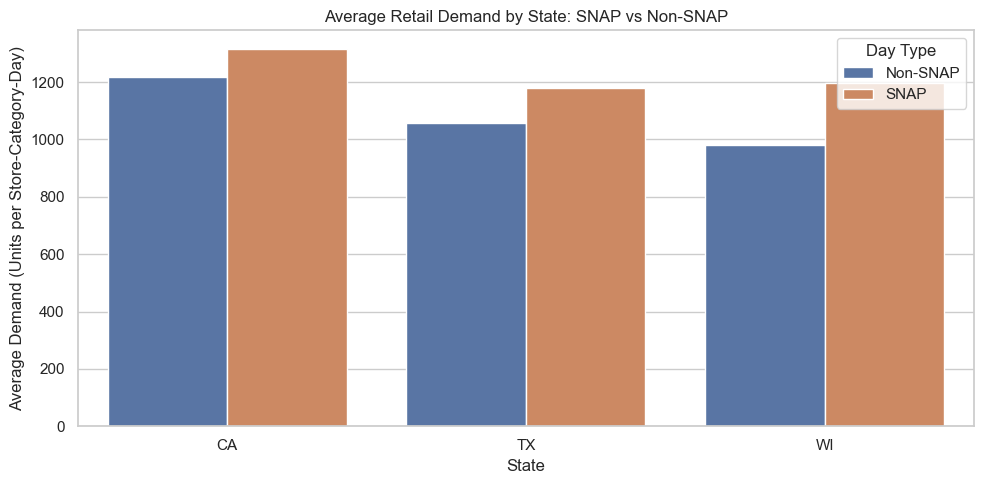

In [83]:
# 11.4.2 Visualize average demand by state and SNAP status
plt.figure(figsize=(10, 5))

sns.barplot(
    data=snap_state_demand,
    x="state_id",
    y="mean",
    hue="day_type"
)

plt.title("Average Retail Demand by State: SNAP vs Non-SNAP")
plt.xlabel("State")
plt.ylabel("Average Demand (Units per Store-Category-Day)")
plt.legend(title="Day Type")

plt.tight_layout()
plt.show()

### SNAP Demand by State — Key Findings

The state-level analysis shows that average retail demand is higher during SNAP periods in all three states represented in the M5 dataset.

In California, average demand increases from approximately **1,217.15 units** during non-SNAP periods to **1,314.32 units** during SNAP periods, representing a **7.98% difference**.

In Texas, average demand increases from approximately **1,057.68 units** to **1,179.19 units**, representing an **11.49% difference**.

**Wisconsin** shows the largest difference. Average demand increases from approximately **982.06 units** during non-SNAP periods to **1,195.95 units** during SNAP periods, representing a **21.78% difference**.

The results therefore show that the observed relationship between SNAP availability and demand is present across all three states, although its magnitude varies by state.

These differences suggest that SNAP availability may provide useful predictive information when combined with geographic information such as state and store. However, the analysis is descriptive and does not establish that SNAP availability itself causes higher demand. Differences in timing, seasonality, store characteristics, and other factors may also contribute to the observed patterns.

**Forecasting implication:** The varying SNAP-associated demand patterns suggest that the relationship between snap and demand may differ by state. Including both snap and state_id in the forecasting model may help capture these differences, although their predictive value must be validated.

### SNAP Demand Difference by State

The previous analysis compared absolute average demand between SNAP and non-SNAP periods. This visualization focuses on the relative percentage difference within each state.

Using percentages makes it easier to compare the magnitude of the SNAP/non-SNAP difference across states, regardless of their different baseline demand levels.

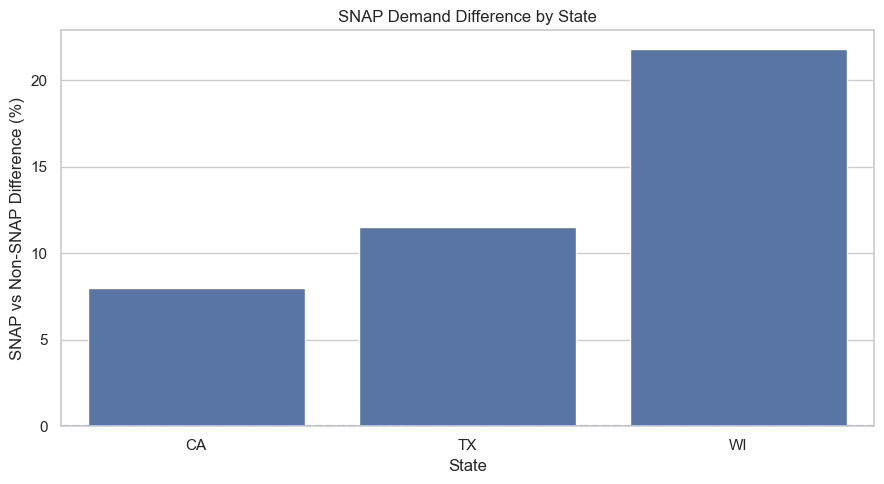

In [84]:
# 11.4.3 Visualize the percentage difference between SNAP and non-SNAP demand

plt.figure(figsize=(9, 5))

sns.barplot(
    data=snap_state_pivot,
    x="state_id",
    y="snap_difference_pct"
)

plt.axhline(0, linestyle="--")

plt.title("SNAP Demand Difference by State")
plt.xlabel("State")
plt.ylabel("SNAP vs Non-SNAP Difference (%)")

plt.tight_layout()
plt.show()

### 11.4.3 — Visualizing SNAP Demand Differences Across States

The chart highlights differences in the association between SNAP availability and retail demand across states.

**Wisconsin records the largest positive difference (+21.78%)**, followed by Texas (+11.49%) and California (+7.98%).

These findings suggest that SNAP-associated demand patterns are not uniform across geographical locations.

**Forecasting implication:** State-level variation supports investigating interactions between `snap` and `state_id` when developing the forecasting model, particularly with tree-based algorithms such as XGBoost.

## 11.5 SNAP Demand by Product Category

The previous analyses showed that average demand is higher during SNAP periods overall and across all three states.

However, the M5 dataset contains three distinct product categories — **FOODS, HOUSEHOLD, and HOBBIES** — with substantially different baseline demand levels.

This analysis therefore compares SNAP and non-SNAP demand within each product category. The objective is to determine whether the observed SNAP-related demand difference is consistent across categories or varies depending on the type of products being purchased.

As with the previous analyses, the results are descriptive and do not establish a causal relationship between SNAP availability and demand.

In [ ]:
# 11.5 Compare average demand by product category and SNAP status

snap_category_demand = (
    df.groupby(["category", "snap"])["demand"]
      .agg(["mean", "sum", "median", "count"])
      .reset_index()
)

snap_category_demand["day_type"] = snap_category_demand["snap"].map({
    0: "Non-SNAP",
    1: "SNAP"
})

snap_category_demand

,category,snap,mean,sum,median,count,day_type
0,FOODS,0,2230.363133,28615559,2098.0,12830,Non-SNAP
1,FOODS,1,2614.980952,16474380,2472.0,6300,SNAP
2,HOBBIES,0,317.624240,4075119,294.0,12830,Non-SNAP
3,HOBBIES,1,325.346190,2049681,299.0,6300,SNAP
4,HOUSEHOLD,0,748.352767,9601366,687.0,12830,Non-SNAP
5,HOUSEHOLD,1,774.492698,4879304,715.0,6300,SNAP


### SNAP Demand Difference by Product Category

To compare the magnitude of the difference across categories, the percentage difference between SNAP and non-SNAP demand is calculated separately for each category.

The calculation uses non-SNAP average demand as the reference point:

\[
\text{SNAP Difference (\%)} =
\frac{\text{SNAP Average Demand} -
\text{Non-SNAP Average Demand}}
{\text{Non-SNAP Average Demand}}
\times 100
\]

This allows the categories to be compared on a relative basis even though their absolute demand levels differ substantially.

In [86]:

# 11.5.1 — SNAP demand differences by product category

# Recreate the category-level SNAP summary
snap_category_demand = (
    df.groupby(["category", "snap"])["demand"]
    .agg(["mean", "sum", "median", "count"])
    .reset_index()
)

# Pivot SNAP and non-SNAP averages into separate columns
snap_category_pivot = (
    snap_category_demand
    .pivot(index="category", columns="snap", values="mean")
    .rename(columns={
        0: "non_snap_avg",
        1: "snap_avg"
    })
    .reset_index()
)

# Calculate relative percentage difference
snap_category_pivot["snap_difference_pct"] = (
    (snap_category_pivot["snap_avg"] - snap_category_pivot["non_snap_avg"])
    / snap_category_pivot["non_snap_avg"]
) * 100

display(snap_category_pivot)


snap,category,non_snap_avg,snap_avg,snap_difference_pct
0,FOODS,2230.363133,2614.980952,17.244628
1,HOBBIES,317.624240,325.346190,2.431159
2,HOUSEHOLD,748.352767,774.492698,3.492996


### 11.5.1 — Percentage Difference in SNAP Demand by Category

The percentage comparison reveals that SNAP-associated demand differences vary considerably across product categories.

**FOODS records the largest positive difference (+17.24%)**, compared with HOUSEHOLD (+3.49%) and HOBBIES (+2.43%).

This suggests that the relationship between SNAP availability and retail demand is substantially stronger for FOODS than for the other categories.

**Forecasting implication:** The results support investigating interactions between `snap` and `category`, allowing the forecasting model to capture category-specific demand patterns.

### 11.5.2 SNAP vs Non-SNAP Demand by Product Category

The following visualization compares average demand during SNAP and non-SNAP periods across FOODS, HOUSEHOLD, and HOBBIES.

The absolute-demand comparison is useful for understanding the actual scale of demand, while the percentage comparison provides a fairer view of the relative difference between SNAP and non-SNAP periods within each category.

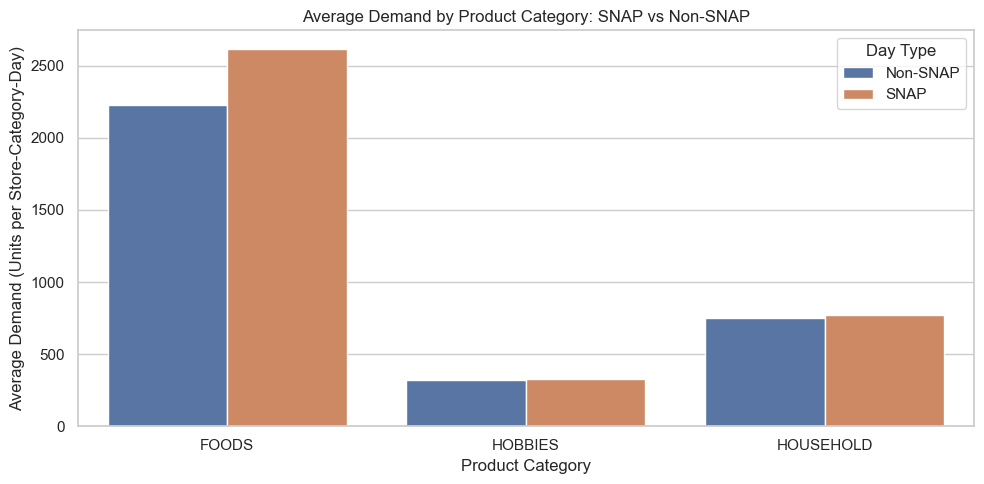

In [88]:

# 11.5.2 — Visualize average demand by category and SNAP status

# Add descriptive labels for SNAP status
snap_category_demand["day_type"] = (
    snap_category_demand["snap"].map({
        0: "Non-SNAP",
        1: "SNAP"
    })
)

# Create grouped bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    data=snap_category_demand,
    x="category",
    y="mean",
    hue="day_type",
    hue_order=["Non-SNAP", "SNAP"],
    errorbar=None
)

plt.title("Average Demand by Product Category: SNAP vs Non-SNAP")
plt.xlabel("Product Category")
plt.ylabel("Average Demand (Units per Store-Category-Day)")
plt.legend(title="Day Type")

plt.tight_layout()
plt.show()


### 11.5.2 — Visualizing SNAP Demand by Product Category

The grouped bar chart shows higher average demand on SNAP days across all three product categories.

**FOODS exhibits the strongest positive difference (+17.24%)**, with average demand increasing from **2,230.36 to 2,614.98 units** per store-category-day.

In contrast, HOUSEHOLD (+3.49%) and HOBBIES (+2.43%) display comparatively small differences.

**Forecasting implication:** These patterns suggest that SNAP availability may provide more useful predictive information for FOODS than for other categories. This should be tested during model evaluation.

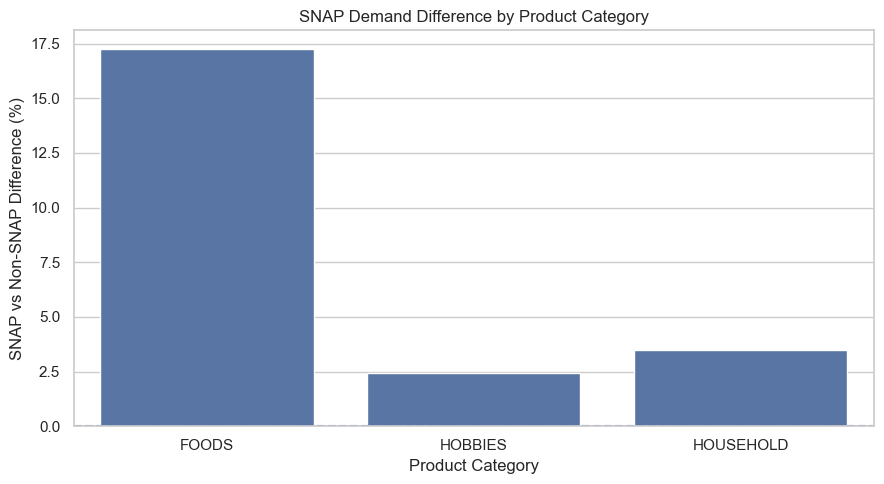

In [89]:
# 11.5.3 — Visualize the relative SNAP demand difference by category

plt.figure(figsize=(9, 5))

sns.barplot(
    data=snap_category_pivot,
    x="category",
    y="snap_difference_pct"
)

plt.axhline(0, linestyle="--")

plt.title("SNAP Demand Difference by Product Category")
plt.xlabel("Product Category")
plt.ylabel("SNAP vs Non-SNAP Difference (%)")

plt.tight_layout()
plt.show()

### 11.5.3 — SNAP Demand Percentage Difference by Product Category

The percentage comparison highlights substantial variation in SNAP-associated demand across product categories.

**FOODS records the largest positive difference (+17.24%)**, considerably exceeding HOUSEHOLD (+3.49%) and HOBBIES (+2.43%).

This suggests that SNAP availability is more strongly associated with demand variation in FOODS than in the other categories.

**Forecasting implication:** Category-specific SNAP patterns support retaining `snap` and `category` as candidate predictors and evaluating whether their interaction improves forecasting accuracy.

In [90]:
# 11.5.4 — Calculate the percentage difference for HOUSEHOLD
household_difference_pct = (
    (774.492698 - 748.352767)
    / 748.352767
) * 100

print(f"HOUSEHOLD SNAP difference: {household_difference_pct:.2f}%")

HOUSEHOLD SNAP difference: 3.49%


### HOUSEHOLD — SNAP Demand Difference

The HOUSEHOLD category records **+3.49% higher average demand on SNAP days** compared with non-SNAP days (774.49 vs. 748.35 units).

This indicates a modest positive association between SNAP availability and HOUSEHOLD demand, considerably smaller than the difference observed for FOODS (+17.24%).

**Forecasting implication:** SNAP availability may provide some predictive information for HOUSEHOLD demand, although its contribution requires validation.

### SNAP Demand by Product Category — Key Findings

SNAP-associated demand differences vary substantially across product categories.

**FOODS records the largest positive difference (+17.24%)**, with average demand increasing from 2,230.36 units on non-SNAP days to 2,614.98 units on SNAP days.

In comparison, HOUSEHOLD (+3.49%) and HOBBIES (+2.43%) show considerably smaller differences.

These findings indicate that the association between SNAP availability and demand is strongest in FOODS. However, the differences are descriptive and may also reflect seasonality, pricing, and other factors.

**Forecasting implication:** Retaining `snap` and `category` as predictive features may help the model capture category-specific demand patterns, particularly through interactions between these variables.

## 11.8 — SNAP Availability and Retail Demand: Final Findings

**Research Question:** How does Walmart's retail demand differ between SNAP and non-SNAP days, and can SNAP availability provide useful information for demand forecasting?

### Key Findings

The analysis identifies a consistent positive association between SNAP availability and observed retail demand.

- **Overall demand:** SNAP days record **+12.70% higher average demand** than non-SNAP days (1,238.27 vs. 1,098.78 units per store-category-day).
- **State-level differences:** Wisconsin shows the largest positive difference (+21.78%), followed by Texas (+11.49%) and California (+7.98%).
- **Category-level differences:** FOODS records the strongest positive difference (+17.24%), compared with HOUSEHOLD (+3.49%) and HOBBIES (+2.43%).

These results demonstrate that SNAP-associated demand differences vary across geographic markets and product categories.

### Forecasting Implications

The findings support retaining `snap`, `state_id`, `store_id`, and `category` as candidate forecasting features. Tree-based models such as XGBoost can investigate interactions between these variables alongside historical demand, seasonality, pricing, and calendar features.

However, these relationships are observational and do not establish causation. Their actual contribution to predictive accuracy must be assessed through time-based model validation.

### Conclusion — Answer to the Research Question

**Walmart's average retail demand is higher on SNAP days, with substantial variation across states and product categories.**

SNAP availability is therefore a promising external predictor for retail demand forecasting, particularly for FOODS, but its forecasting value remains to be confirmed through model evaluation.

## 12 — Price and Retail Demand Analysis

### Research Question

**What is the relationship between average selling price and Walmart's retail demand, and can pricing information help improve demand forecasting?**

### Objective

This analysis investigates how retail demand varies with average selling price across Walmart's stores and product categories.

During data preparation, product-level prices were aggregated to the **store-category-week level** to create `avg_sell_price`, which was subsequently aligned with daily demand observations.

The analysis examines:

- **Descriptive statistics:** Distribution and variability of average selling price and demand.
- **Price–demand relationships:** Correlations and visual patterns between selling prices and demand.
- **Category-level differences:** Whether price–demand associations vary across product categories.

### Forecasting Relevance

Understanding price–demand relationships can help assess whether `avg_sell_price` and price-change variables provide useful information for predicting future retail demand.

**Important consideration:** The analysis is descriptive, not causal. Differences may reflect product mix, store characteristics, promotions, seasonality, holidays, and SNAP availability. Furthermore, aggregated average prices do not represent the price of a single product.

In [91]:
# 12.1 Descriptive statistics for demand and average selling price

price_demand_stats = df[
    ["demand", "avg_sell_price"]
].describe()

price_demand_stats

,demand,avg_sell_price
count,57390.000000,57390.000000
mean,1144.718749,4.647058
std,1049.785911,1.035789
min,0.000000,2.759773
25%,354.000000,3.303152
50%,702.000000,5.353571
75%,1734.000000,5.480662
max,6488.000000,5.841174


### 12.1 — Descriptive Statistics of Price and Demand

The dataset contains **57,390 observations** with complete values for both demand and average selling price.

Daily demand averages **1,144.72 units per store-category**, with a median of **702 units** and a standard deviation of **1,049.79 units**. The large difference between the mean and median indicates a right-skewed distribution with substantial demand variability.

Average selling price is **4.65**, with a median of **5.35**, a standard deviation of **1.04**, and values ranging from **2.76 to 5.84**.

These statistics establish the distributions of demand and average selling price but do not yet reveal the relationship between them.

**Forecasting implication:** The observed variation supports investigating whether pricing information provides additional predictive value beyond historical demand, store characteristics, and product categories.

## 12.2 Correlation Between Price and Demand

The Pearson correlation coefficient is used to quantify the direction and strength of the linear relationship between average selling price and demand.

The coefficient ranges from **−1 to +1**:

- Values closer to **−1** indicate a strong negative linear relationship.
- Values closer to **0** indicate a weak or limited linear relationship.
- Values closer to **+1** indicate a strong positive linear relationship.

A correlation does not establish causation. In particular, retail prices may themselves respond to demand conditions, promotions, product characteristics, or seasonal periods.

In [92]:
#12.2 Calculate Pearson correlation between average selling price and demand

price_demand_corr = df[
    ["avg_sell_price", "demand"]
].corr()

price_demand_corr

,avg_sell_price,demand
avg_sell_price,1.000000,-0.765268
demand,-0.765268,1.000000


In [93]:
# 12.2.1 — Extract the correlation coefficient

correlation = df["avg_sell_price"].corr(df["demand"])

print(f"Pearson correlation between price and demand: {correlation:.4f}")

Pearson correlation between price and demand: -0.7653


### 12.2 — Correlation Between Average Selling Price and Demand

The Pearson correlation between `avg_sell_price` and `demand` is **−0.7653**, indicating a strong negative linear association across the dataset.

Overall, observations with higher average selling prices tend to have lower daily demand.

However, this relationship may partly reflect differences in product categories, store characteristics, and product composition rather than the effect of price changes themselves.

**Forecasting implication:** Average selling price is a potentially informative predictor, but category-level and within-group analysis is necessary before interpreting the strength of its relationship with demand.

## 12.3 Correlation Analysis

A correlation analysis is used to examine the linear relationships between the main numerical variables in the cleaned dataset.

The correlation matrix provides an overview of how variables such as demand, selling price, price changes, SNAP availability, and calendar-related numerical variables are associated with one another.

A heatmap is used to visualize these relationships.

The Pearson correlation coefficient ranges from:

- **+1** — strong positive linear relationship
- **0** — little or no linear relationship
- **−1** — strong negative linear relationship

Correlation measures association rather than causation. Therefore, a strong correlation between two variables does not mean that one variable causes changes in the other.

The heatmap is used primarily as an exploratory tool to identify potentially useful relationships and possible redundancy among numerical variables before machine-learning feature engineering.

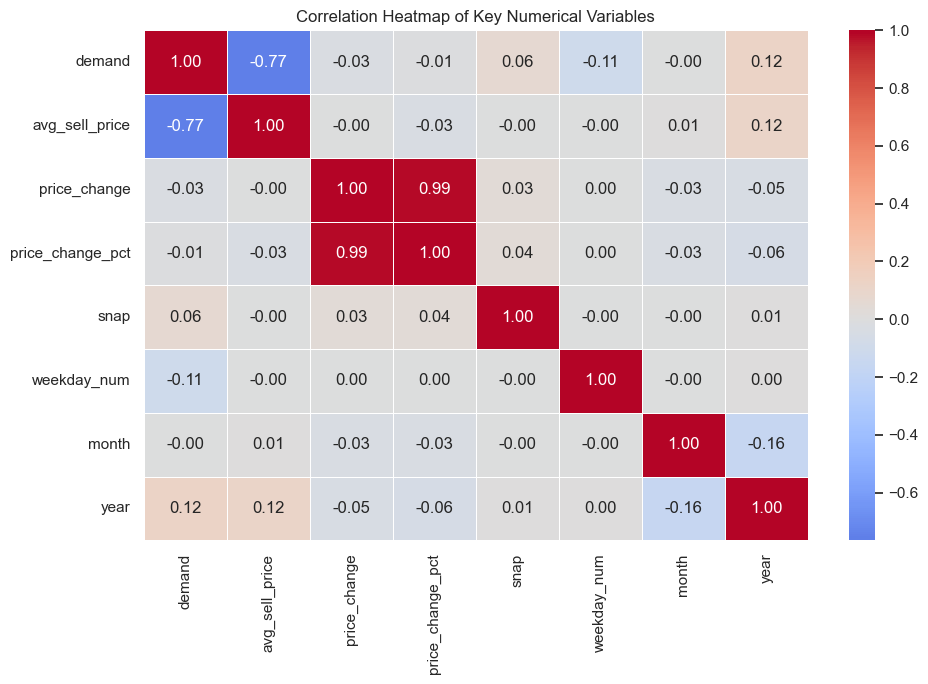

In [94]:
# 12.3 Create a correlation heatmap for key numerical variables
correlation_columns = [
    "demand",
    "avg_sell_price",
    "price_change",
    "price_change_pct",
    "snap",
    "weekday_num",
    "month",
    "year"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Key Numerical Variables")
plt.tight_layout()
plt.show()

### 12.3 — Correlation Heatmap of Numerical Variables

The correlation heatmap reveals a **strong negative relationship between average selling price and demand (r = −0.77)**, while most other numerical variables exhibit weak linear associations with demand.

Price change (−0.03), percentage price change (−0.01), SNAP availability (+0.06), and year (+0.12) show comparatively weak correlations.

Notably, `price_change` and `price_change_pct` are highly correlated (**r = +0.99**), indicating substantial overlap between these features.

**Forecasting implication:** `avg_sell_price` is a promising candidate predictor, but its strong overall correlation may reflect differences in product categories rather than price effects within individual categories. Meanwhile, weak linear correlations do not rule out nonlinear relationships that machine-learning models may capture.

## 12.4 Price–Demand Visualization

The scatter plot provides a visual representation of the relationship between average selling price and demand.

Because the dataset contains many observations, transparency is used to make areas of higher observation density easier to identify.

A trend line is also included to provide a visual indication of the overall linear relationship. The trend line should be interpreted as descriptive rather than causal.

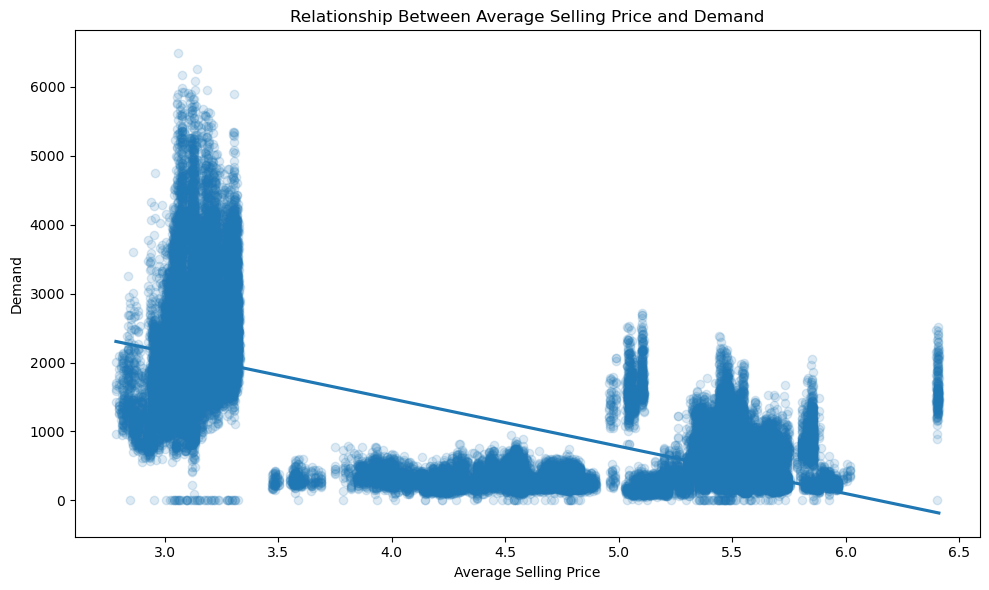

In [74]:
# 12.4 Visualize the relationship between average selling price and demand
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="avg_sell_price",
    y="demand",
    scatter_kws={"alpha": 0.15},
    line_kws={}
)

plt.title("Relationship Between Average Selling Price and Demand")
plt.xlabel("Average Selling Price")
plt.ylabel("Demand")

plt.tight_layout()
plt.show()

### 12.4 — Visualizing the Relationship Between Price and Demand

The scatter plot reveals a **strong negative overall association** between average selling price and retail demand, consistent with the Pearson correlation of **−0.7653**.

Lower-priced observations generally exhibit higher and more variable demand, while higher-priced observations tend to have lower demand.

However, the visible clusters suggest that differences between product categories and store-category combinations

## 12.5 Price–Demand Relationship by Product Category

The overall price-demand relationship may be influenced by differences between product categories.

FOODS, HOUSEHOLD, and HOBBIES have substantially different demand levels, so a single correlation across all observations may not fully describe the relationship within each category.

The correlation is therefore calculated separately for each product category. This provides a more detailed view of whether the relationship between average selling price and demand is consistent across categories.

In [95]:
# 12.5 Calculate Pearson correlation between price and demand by category

category_price_corr = (
    df.groupby("category")
      .apply(
          lambda group: group["avg_sell_price"].corr(group["demand"]),
          include_groups=False
      )
      .reset_index(name="price_demand_correlation")
)

category_price_corr

,category,price_demand_correlation
0,FOODS,0.374719
1,HOBBIES,0.233649
2,HOUSEHOLD,-0.367204


### 12.5 — Price–Demand Correlation by Product Category

The category-level analysis reveals substantial differences in the relationship between average selling price and retail demand.

- **FOODS:** Moderate positive correlation (+0.3747).
- **HOBBIES:** Weak positive correlation (+0.2336).
- **HOUSEHOLD:** Moderate negative correlation (−0.3672).

These findings contrast with the **strong negative overall correlation (−0.7653)**, demonstrating that the aggregate relationship does not accurately represent every product category.

The contrasting patterns suggest that category composition influences the overall correlation. However, these results remain observational and do not establish causal price effects.

**Forecasting implication:** Including both `avg_sell_price` and `category` may help machine-learning models capture category-specific relationships. Further analysis within individual store-category series would help distinguish price changes over time from differences between stores.

## 12.6 Price–Demand Relationship Across Categories

The category-level visualization allows the price-demand relationship to be examined separately for FOODS, HOUSEHOLD, and HOBBIES.

This is useful because differences in baseline demand between categories can influence the overall relationship observed in the combined dataset.

The visualizations are descriptive and are intended to identify patterns that may be useful for feature engineering and model development.

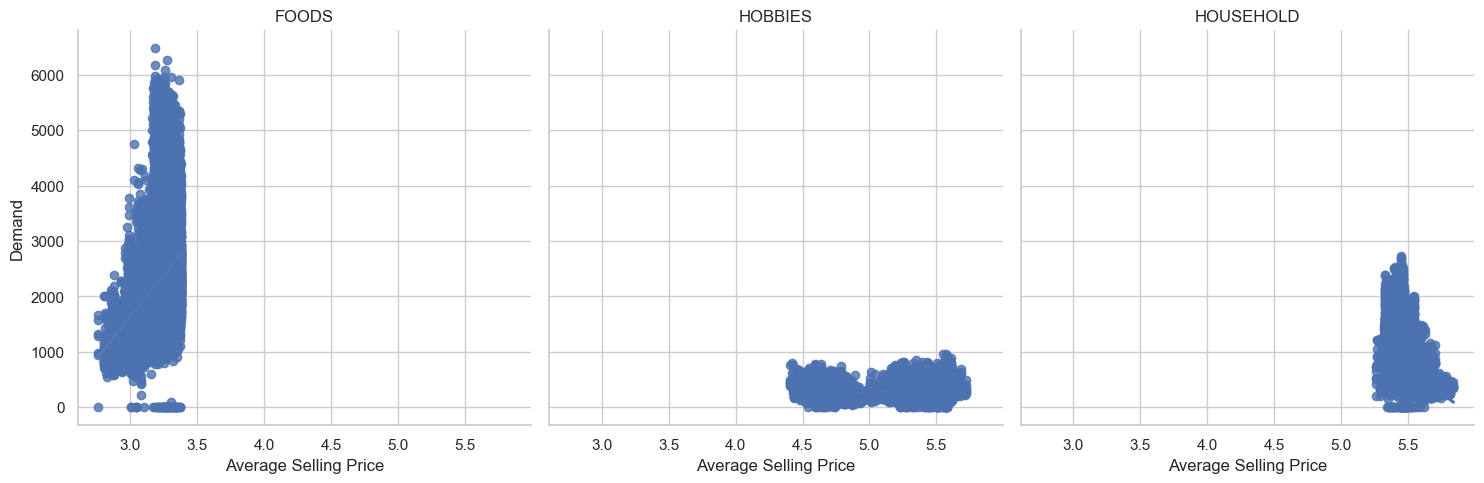

In [96]:
# 12.6 Plot price-demand relationships separately by category

g = sns.lmplot(
    data=df,
    x="avg_sell_price",
    y="demand",
    col="category",
    height=5,
    aspect=1
)

g.set_axis_labels("Average Selling Price", "Demand")
g.set_titles("{col_name}")

plt.show()

### 12.6 — Visualizing Price–Demand Relationships by Product Category

The category-level scatter plots reveal contrasting relationships between average selling price and retail demand.

**FOODS (+0.3747)** and **HOBBIES (+0.2336)** exhibit positive correlations, while **HOUSEHOLD (−0.3672)** shows a negative correlation.

The plots also highlight substantial differences in demand levels and selling-price ranges across categories. These differences help explain why the overall negative correlation (−0.7653) does not represent every category.

**Forecasting implication:** Price–demand relationships vary by product category, supporting the inclusion of `avg_sell_price` and `category` as candidate features in models capable of learning nonlinear interactions.

## 12.7 Demand and Weekly Price Changes

The previous analysis examined the relationship between the level of average selling price and demand.

However, the absolute price level can reflect structural differences between product categories. A complementary analysis is therefore to examine whether demand differs when prices increase, decrease, or remain unchanged from the previous week.

The `price_change` variable measures the absolute change in average selling price compared with the previous week for each store-category combination.

This analysis provides a descriptive view of whether weekly pricing movements coincide with differences in observed demand.

In [97]:
# 12.7 Create a categorical price-change indicator

df["price_change_direction"] = np.select(
    [
        df["price_change"] > 0,
        df["price_change"] < 0,
        df["price_change"] == 0
    ],
    [
        "Price increase",
        "Price decrease",
        "No price change"
    ],
    default="No previous week"
)

# Compare demand across price-change directions

price_change_demand = (
    df.groupby("price_change_direction")["demand"]
      .agg(["mean", "sum", "median", "count"])
      .reset_index()
)

price_change_demand

,price_change_direction,mean,sum,median,count
0,No previous week,904.485714,189942,447.0,210
1,No price change,422.110282,1018130,344.0,2412
2,Price decrease,1108.522177,30140718,688.0,27190
3,Price increase,1245.435456,34346619,804.0,27578


### 12.7 — Retail Demand by Price-Change Direction

This analysis compares average daily demand across different weekly price-change categories.

Observations classified as **price increases** record the highest average demand (**1,245.44 units**), followed by **price decreases (1,108.52 units)** and **no price change (422.11 units)**.

Average demand is approximately **+12.35% higher** in the price-increase group than in the price-decrease group.

These differences are descriptive and do not demonstrate that price increases cause higher demand. They may reflect product-category composition, store characteristics, seasonality, and other factors.

**Forecasting implication:** Price-change direction may contain useful predictive information, but its contribution should be evaluated alongside average selling price, product category, store, and historical demand.

In [98]:
# 12.7.1 — Exclude the first week because there is no previous week
# from which to calculate a price change.

price_change_valid = price_change_demand[
    price_change_demand["price_change_direction"] != "No previous week"
].copy()

# Extract average demand for each price-change direction
price_increase_avg = price_change_valid.loc[
    price_change_valid["price_change_direction"] == "Price increase",
    "mean"
].iloc[0]

price_decrease_avg = price_change_valid.loc[
    price_change_valid["price_change_direction"] == "Price decrease",
    "mean"
].iloc[0]

no_change_avg = price_change_valid.loc[
    price_change_valid["price_change_direction"] == "No price change",
    "mean"
].iloc[0]

# Calculate relative differences
increase_vs_decrease_pct = (
    (price_increase_avg - price_decrease_avg)
    / price_decrease_avg
) * 100

increase_vs_no_change_pct = (
    (price_increase_avg - no_change_avg)
    / no_change_avg
) * 100

decrease_vs_no_change_pct = (
    (price_decrease_avg - no_change_avg)
    / no_change_avg
) * 100

print(f"Price increase vs price decrease: {increase_vs_decrease_pct:.2f}%")
print(f"Price increase vs no price change: {increase_vs_no_change_pct:.2f}%")
print(f"Price decrease vs no price change: {decrease_vs_no_change_pct:.2f}%")

Price increase vs price decrease: 12.35%
Price increase vs no price change: 195.05%
Price decrease vs no price change: 162.61%


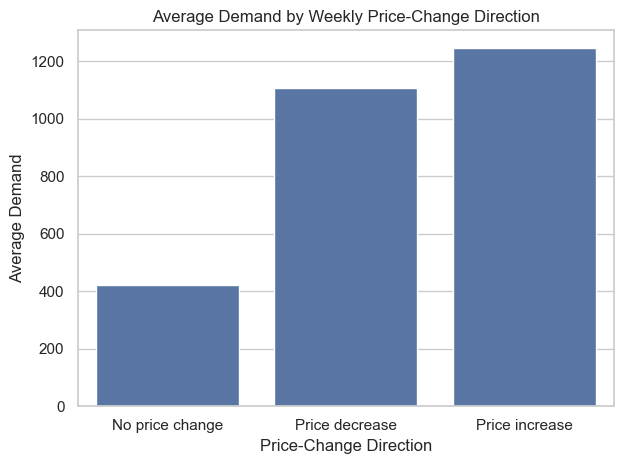

In [99]:
# 12.7.2 — Visualize average demand by weekly price-change direction

sns.barplot(
    data=price_change_valid,
    x="price_change_direction",
    y="mean"
)

plt.title("Average Demand by Weekly Price-Change Direction")
plt.xlabel("Price-Change Direction")
plt.ylabel("Average Demand")
plt.tight_layout()
plt.show()

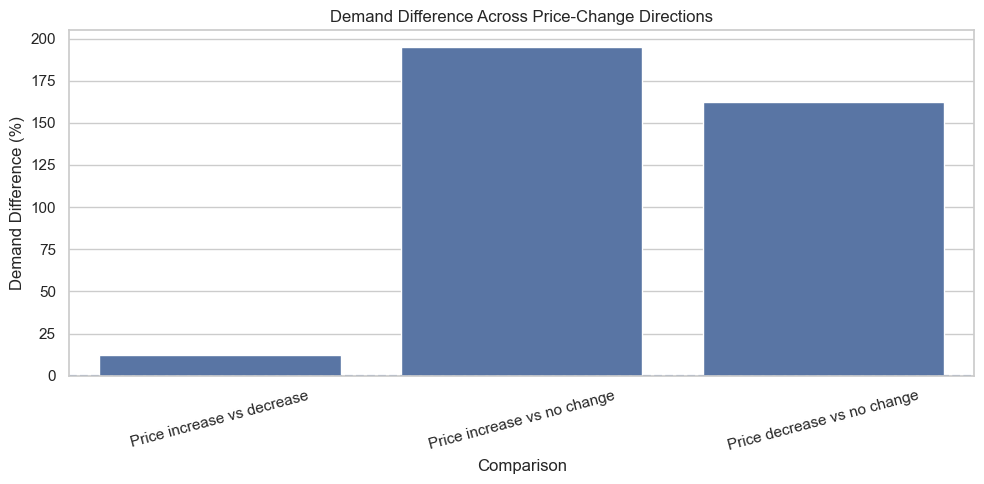

In [100]:
# 12.7.3 — Create a table for relative comparison
price_change_comparison = pd.DataFrame({
    "comparison": [
        "Price increase vs decrease",
        "Price increase vs no change",
        "Price decrease vs no change"
    ],
    "difference_pct": [
        increase_vs_decrease_pct,
        increase_vs_no_change_pct,
        decrease_vs_no_change_pct
    ]
})

plt.figure(figsize=(10, 5))

sns.barplot(
    data=price_change_comparison,
    x="comparison",
    y="difference_pct"
)

plt.axhline(0, linestyle="--")

plt.title("Demand Difference Across Price-Change Directions")
plt.xlabel("Comparison")
plt.ylabel("Demand Difference (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### 12.7.1–12.7.3 — Demand Differences Across Price-Change Directions

The comparison reveals substantial differences in average retail demand across weekly price-change categories.

- **Price increase vs. price decrease:** +12.35%
- **Price increase vs. no price change:** +195.05%
- **Price decrease vs. no price change:** +162.61%

The visualizations confirm that observations classified as price increases have the highest average demand, while those with unchanged prices have the lowest.

However, these differences should not be interpreted as causal price effects. The groups may differ in store composition, product categories, seasonality, and other demand-related factors. Additionally, price changes are calculated from aggregated weekly average prices rather than individual product prices.

**Forecasting implication:** Price-change direction may provide useful predictive information, particularly when combined with store, category, and historical demand features. Its actual contribution must be evaluated during model validation.

## 12.8 — Price and Retail Demand: Final Findings

**Research Question:** What is the relationship between average selling price and Walmart's retail demand, and can pricing information help improve demand forecasting?

### Key Findings

The analysis reveals that price–demand relationships differ substantially across product categories and weekly price-change conditions.

- **Overall correlation:** Average selling price and demand exhibit a strong negative correlation (**r = −0.7653**).
- **Category-level correlations:** FOODS (+0.3747) and HOBBIES (+0.2336) show positive associations, while HOUSEHOLD (−0.3672) exhibits a negative association.
- **Weekly price changes:** Average demand is **+12.35% higher** during price-increase observations than during price-decrease observations.
- **Unchanged prices:** Demand during price-increase and price-decrease observations is **+195.05%** and **+162.61% higher**, respectively, than during observations with no price change.

These findings demonstrate that the strong overall negative correlation does not represent every product category. They also show that observed demand differs considerably across price-change conditions.

### Forecasting Implications

The results support retaining `avg_sell_price`, `price_change`, and `price_change_pct` as candidate predictive features alongside historical demand, store, category, seasonality, SNAP, and event information.

However, the analysis is observational. Differences in product composition, stores, promotions, and seasonal patterns may influence both prices and demand. Additionally, weekly average price changes do not necessarily represent price adjustments for individual products.

The predictive contribution of pricing features must therefore be established through time-based model validation.

### Conclusion — Answer to the Research Question

**Average selling price is strongly negatively correlated with retail demand overall, but the relationship varies across product categories and price-change conditions.**

Pricing information is therefore a promising forecasting input, particularly when considered alongside store, category, and historical demand features. Its actual contribution to forecasting accuracy remains to be tested.

# 13 — Key EDA Findings and Business Insights

### Objective

This section consolidates the major findings from the exploratory data analysis and translates them into actionable business insights and machine-learning forecasting implications.

The analysis examined retail demand across **time, stores, states, product categories, holidays, SNAP availability, and pricing**.

The objective is to identify the most relevant demand patterns, understand their potential business significance, and establish a data-driven foundation for feature selection.

### From EDA to Forecasting

The findings help guide the selection of historical demand, calendar, categorical, and external variables for the forecasting model.

However, **descriptive relationships do not guarantee predictive value**. The final contribution of each feature will be assessed through time-based validation and model evaluation.

The following sections summarize the key findings and their implications for retail demand forecasting.

## 13.1 — Demand and Time-Based Patterns

The dataset contains **57,390 observations** across 10 stores, 3 states, 3 product categories, and 1,913 historical days.

Average daily demand is **1,144.72 units per store-category**, compared with a median of **702 units**, indicating a right-skewed distribution with substantial variability.

The time-series analysis identifies three important patterns:

- **Weekly seasonality:** Saturday records the highest average demand (1,384.90 units), approximately **+38.4% above Wednesday** (1,000.33 units).
- **Monthly seasonality:** August has the highest average demand (1,198.22 units; **+4.67%** relative to the overall average), while May has the lowest (1,083.46 units; **−5.35%**).
- **Long-term trend:** Average demand generally increases over the historical period, although growth is not uniform across years.

### Business and Forecasting Implications

These patterns suggest that retail inventory planning should account for higher weekend demand, recurring monthly fluctuations, and changes in demand over time.

For forecasting, the findings support incorporating **weekday, month, year, seasonal indicators, historical demand lags, and rolling statistics** to capture recurring patterns and longer-term changes.

## 13.2 — Geographic and Store-Level Differences

Retail demand varies substantially across states and individual Walmart stores.

- **California:** Highest average demand (1,249.15 units; **+9.12%** relative to the overall average).
- **Texas:** Average demand of 1,097.69 units (**−4.11%**).
- **Wisconsin:** Lowest state-level average demand at 1,052.50 units (**−8.06%**).

California accounts for **43.65% of total demand**, although this partly reflects its larger number of stores (four versus three each in Texas and Wisconsin).

Store-level differences are even more pronounced. **CA_3 records the highest average demand (1,949.50 units; +70.30%)**, while **CA_4 records the lowest (715.05 units; −37.53%)**.

The substantial variation between CA_3 and CA_4 demonstrates that stores within the same state can exhibit very different demand patterns.

### Business and Forecasting Implications

These findings suggest that inventory allocation and replenishment decisions should consider **individual store demand**, rather than relying exclusively on state-level averages.

For forecasting, retaining `store_id` and `state_id` can help models capture geographic and store-specific differences in demand.

## 13.3 — Product Category Differences

Product category is a major source of variation in Walmart's retail demand.

- **FOODS:** Highest average demand (**2,357.03 units**), representing **68.63% of total demand** and **+105.90% above the overall average**.
- **HOUSEHOLD:** Average demand of **756.96 units**, accounting for **22.04% of total demand**.
- **HOBBIES:** Lowest average demand (**320.17 units**), contributing **9.32% of total demand**.

FOODS generates approximately **3.11 times the average demand of HOUSEHOLD** and **7.36 times that of HOBBIES**, highlighting substantial differences across product categories.

### Business and Forecasting Implications

These findings suggest that inventory planning and replenishment strategies should account for category-specific demand levels rather than applying uniform assumptions across the product portfolio.

For forecasting, retaining `category` as a predictive feature is essential for capturing differences in demand magnitude and potentially distinct seasonal and behavioral patterns. Forecasting performance should also be evaluated by category to ensure that accuracy is not dominated by the high-volume FOODS category.

## 13.4 — Calendar Events and SNAP Availability

Calendar events and SNAP availability are associated with notable differences in Walmart's retail demand.

### Calendar Events

- **Event vs. non-event days:** Average demand is **1,088.50 units** on event days, approximately **−5.32%** compared with non-event days (1,149.64 units).
- **Event types:** Sporting events show demand **+4.24% above** the overall average, while National events show demand **−14.22% below** it.
- **Individual events:** LaborDay records demand **+22.75% above** the overall average, while Thanksgiving records **−38.47% below** it.
- **Christmas:** Demand is consistently near zero across five historical Christmas dates, averaging approximately **0.37–0.67 units per store-category-day**.

These differences demonstrate that individual holidays can have substantially different demand patterns.

### SNAP Availability

Average demand during SNAP periods is **1,238.27 units**, compared with **1,098.78 units** during non-SNAP periods, representing an observed increase of **+12.70%**.

The association varies across states and categories, with **FOODS showing +17.24% higher demand** during SNAP periods.

### Business and Forecasting Implications

These findings suggest that inventory planning should account for holiday-specific demand fluctuations and SNAP-related demand patterns, particularly in FOODS.

For forecasting, retaining **event indicators, event types, and SNAP availability** may help capture calendar-related demand variation.

However, these associations are descriptive rather than causal, and their predictive value must be confirmed through time-based model evaluation.

## 13.5 — Pricing and Demand

The analysis reveals a complex relationship between average selling price and retail demand.

- **Overall correlation:** Average selling price and demand show a strong negative association (**r = −0.7653**).
- **Category-level correlations:** FOODS (**+0.3747**) and HOBBIES (**+0.2336**) exhibit positive associations, while HOUSEHOLD (**−0.3672**) shows a negative association.
- **Weekly price changes:** Average demand is approximately **+12.35% higher** during price-increase observations than during price-decrease observations.

These differences demonstrate that aggregate price-demand relationships can conceal important variation across product categories.

### Business and Forecasting Implications

Pricing patterns should be interpreted within their broader retail context, including product category, store, seasonality, and promotional activity. The observed associations do not establish causal price effects.

For forecasting, `avg_sell_price`, `price_change`, and `price_change_pct` remain candidate predictive features. Their contribution to forecast accuracy should be evaluated alongside historical demand, calendar events, SNAP availability, and store-category characteristics.

## 13.6 — Translating EDA Findings into Model Features

The EDA provides a data-driven foundation for selecting features that capture temporal patterns, geographic differences, product characteristics, and external influences on retail demand.

The following features will be considered during model development:

| EDA Finding | Candidate Features | Forecasting Purpose |
|---|---|---|
| Weekly seasonality | `weekday_num`, weekday sine/cosine | Capture recurring weekday demand patterns |
| Monthly and annual variation | `month`, `year`, `time_index`, seasonal encodings | Capture seasonality and longer-term trends |
| Geographic differences | `state_id`, `store_id` | Capture regional and store-specific demand |
| Category-level differences | `category` | Capture differences across product groups |
| Holidays and special events | Event names and types | Capture event-related demand fluctuations |
| SNAP availability | `snap` | Capture SNAP-associated demand patterns |
| Pricing relationships | `avg_sell_price`, `price_change`, `price_change_pct` | Capture pricing information and weekly movements |
| Historical demand | `lag_28`, `lag_35`, `lag_42`, `lag_56`, `lag_84`, `lag_364` | Capture past demand and recurring patterns |
| Demand variability | Rolling means and standard deviations | Capture historical demand levels and fluctuations |

### Machine-Learning Implications

The findings support combining **historical demand features, calendar variables, store and category identifiers, events, SNAP availability, and pricing information** within a unified forecasting framework.

Historical demand features must be calculated using only information available at each forecast origin to prevent data leakage.

Although EDA identifies potentially useful variables, their predictive contribution will be determined through **time-based validation, model comparison, and feature-importance analysis**.

## 13.7 — Business Implications

The EDA findings highlight several opportunities to improve retail demand planning and inventory management.

1. **Improve inventory planning through seasonality:** Higher weekend demand suggests that replenishment schedules and stock availability should account for recurring weekly patterns to reduce potential stockouts and excess inventory.

2. **Optimize store-level inventory allocation:** Significant differences between stores, including those within the same state, support location-specific demand forecasts rather than relying exclusively on regional averages.

3. **Develop category-specific inventory strategies:** FOODS accounts for **68.63% of total demand**, indicating the importance of aligning inventory allocation and replenishment priorities with category-level demand.

4. **Anticipate calendar-related demand fluctuations:** Holidays, special events, and SNAP availability are associated with meaningful demand differences. Incorporating these patterns may improve inventory preparation for periods of unusually high or low demand.

5. **Incorporate pricing information into demand planning:** Category-dependent price-demand relationships suggest that pricing information should be evaluated alongside historical demand, store characteristics, and seasonal factors.

6. **Use historical demand to support forecasting:** Demand lags and rolling statistics can help capture recurring patterns and changing demand levels, supporting more informed replenishment decisions.

### Overall Business Value

Together, these findings provide a foundation for developing more targeted demand forecasts across Walmart's **30 store-category combinations**.

More accurate forecasts could support **better inventory allocation, fewer stockouts, reduced overstocking, and more efficient replenishment planning**. These benefits remain potential outcomes until forecasting performance and operational impact are evaluated.

## 13.8 — Summary of Exploratory Data Analysis

The exploratory data analysis of Walmart's M5 retail dataset identified several important patterns influencing observed demand across **30 store-category combinations**.

The key findings include:

- **Temporal patterns:** Strong weekly seasonality, with Saturday demand **+38.4% higher than Wednesday**, alongside monthly fluctuations and longer-term demand changes.
- **Geographic and store differences:** Demand varies considerably across states and individual stores, highlighting the importance of location-specific forecasting.
- **Product categories:** FOODS accounts for **68.63% of total demand**, demonstrating substantial differences in demand magnitude across categories.
- **Calendar and SNAP effects:** Holidays, special events, and SNAP availability are associated with meaningful demand differences, including consistently near-zero Christmas demand.
- **Pricing relationships:** Price-demand associations vary across categories, indicating that pricing information should be interpreted alongside other retail characteristics.

### Transition to Machine Learning

These findings support developing a forecasting model that combines **historical demand, seasonal patterns, store and category identifiers, calendar events, SNAP availability, and pricing information**.

The next stage will focus on **feature engineering, time-based data splitting, model training, and evaluation**, with XGBoost as the primary machine-learning approach.

The objective is to determine whether these features can produce accurate **28-day demand forecasts** and provide actionable information for inventory and replenishment planning.

# 14 — Conclusion

The exploratory data analysis of Walmart's M5 dataset identified important patterns in retail demand across **30 store-category combinations**, covering 10 stores, 3 states, and 3 product categories.

The analysis revealed strong **weekly seasonality**, substantial differences across stores and product categories, and meaningful associations between demand, calendar events, SNAP availability, and pricing information.

Key findings include Saturday demand being **38.4% higher than Wednesday**, FOODS accounting for **68.63% of total demand**, and consistently near-zero demand during Christmas. Pricing relationships also varied across product categories, highlighting the importance of interpreting demand within its broader retail context.

These findings provide a foundation for developing a forecasting model that combines **historical demand, temporal features, store and category characteristics, calendar events, SNAP availability, and pricing information**.

### Next Steps — Machine-Learning Forecasting

The next stage will focus on:

1. **Feature engineering:** Creating lagged demand, rolling statistics, seasonal indicators, and relevant categorical features.
2. **Time-based validation:** Separating training, validation, and test periods chronologically to prevent data leakage.
3. **Model development:** Training XGBoost to predict retail demand over a **28-day forecasting horizon**.
4. **Model evaluation:** Comparing XGBoost against a seasonal-naive baseline using MAE, RMSE, WAPE, and R².

The objective is to develop a reliable forecasting approach that can support **inventory allocation, replenishment planning, and data-driven retail decision-making**.

## 14.1 — Transition to Machine Learning Forecasting

The exploratory data analysis identified important temporal, geographic, categorical, calendar, SNAP, and pricing patterns in Walmart's retail demand.

These findings provide the foundation for **`03_Machine_Learning_Forecasting.ipynb`**, which develops a comprehensive machine-learning framework combining **time-series forecasting, regression modeling, classification analysis, and model interpretation**.

### Machine-Learning Workflow

The forecasting notebook includes the following stages:

1. **Data preparation:** Prepare the cleaned dataset and organize the 30 store-category time series.

2. **Chronological data splitting:** Establish training, validation, and test periods for a 28-day forecasting horizon.

3. **Feature engineering:** Create lagged demand, rolling statistics, calendar and seasonal features, store and category encodings, event indicators, SNAP variables, and pricing features.

4. **Baseline forecasting:** Establish seasonal-naive and Prophet benchmarks.

5. **Regression modeling:** Train and compare XGBoost, Extra Trees, and Gradient Boosting models for predicting retail demand quantities.

6. **Classification analysis:** Examine demand-related classification outcomes as a complementary machine-learning task, providing an additional perspective beyond numerical demand predictions.

7. **Model evaluation:** Evaluate regression forecasts using MAE, RMSE, WAPE, and R², and assess classification performance using metrics appropriate to the classification target.

8. **Model interpretation:** Examine feature importance, prediction errors, and model behavior to understand the factors influencing results.

9. **Final forecasting:** Generate and evaluate 28-day demand predictions using the selected forecasting approach.

10. **Business implications:** Translate regression, classification, and forecasting findings into actionable insights for inventory planning, replenishment, and retail decision-making.

### Methodological Approach

The analysis follows a **time-aware validation strategy**, avoiding random splitting that could introduce future information into model training.

Historical demand features are constructed with attention to the forecast horizon and data availability to prevent leakage.

Regression models focus on predicting **demand quantities**, while classification provides complementary insights into demand-related outcomes.

### Project Objective

The objective is to compare forecasting approaches, evaluate the contribution of engineered features, and investigate how regression and classification techniques can support more informed retail inventory decisions.